In [2]:
import numpy as np
import pandas as pd
from utils import *
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances

In [3]:
#spectral_data_mpc_mpb = pd.read_csv('../processed_data/mpb_mpc_data.csv')
#del spectral_data_mpc_mpb['Unnamed: 0']

In [4]:
df_spectra_flopp = pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
del df_spectra_flopp['Unnamed: 0']

label_table = (
    df_spectra_flopp.
    query('data_source == "flopp"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table_e = (
    df_spectra_flopp.
    query('data_source == "flopp_e"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table = label_table.merge(label_table_e, on='polymer')
del label_table['index_x']
del label_table['index_y']
label_table = label_table.reset_index()
label_table.columns = ['label', 'polymer']

df_spectra_flopp = df_spectra_flopp.merge(label_table)

y_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,1].to_numpy()
label_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,-1].to_numpy()
X_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,3:-1].to_numpy()
X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

y_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,1].to_numpy()
label_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,-1].to_numpy()
X_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,3:-1].to_numpy()
X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]

wl_list = np.float64(df_spectra_flopp.columns[3:-1])

In [5]:
#df_spectra_flopp = pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
#del df_spectra_flopp['Unnamed: 0']
(df_spectra_flopp.
 groupby(['data_source', 'polymer']).
 count().
 reset_index().
 iloc[:,:3].
 pivot(index='polymer', values='file_name', columns='data_source').reset_index())

data_source,polymer,flopp,flopp_e
0,Acrylonitrile Butadiene Styrene,14,1
1,Cotton,14,12
2,Polyamide,12,6
3,Polycarbonate,8,1
4,Polyethylene,18,49
5,Polyethylene Terephthalate,25,22
6,Polyethylene Vinyl Acetate,10,5
7,Polypropylene,19,66
8,Polystyrene,14,12
9,Polyurethane,13,6


In [6]:
(df_spectra_flopp.
 groupby(['data_source', 'polymer']).
 count().reset_index().iloc[:,:2])

,data_source,polymer
0,flopp,Acrylonitrile Butadiene Styrene
1,flopp,Cotton
2,flopp,Polyamide
3,flopp,Polycarbonate
4,flopp,Polyethylene
5,flopp,Polyethylene Terephthalate
6,flopp,Polyethylene Vinyl Acetate
7,flopp,Polypropylene
8,flopp,Polystyrene
9,flopp,Polyurethane


In [7]:
#spectral_data_mpc_mpb_ = spectral_data_mpc_mpb.copy()

In [8]:
#y_test_2 = spectral_data_mpc_mpb_.loc[np.isnan(spectral_data_mpc_mpb_.merge(label_table, how='left')['label']),:]['polymer'].to_numpy()
#label_test_2 = spectral_data_mpc_mpb_.loc[np.isnan(spectral_data_mpc_mpb_.merge(label_table, how='left')['label']),:]['label'].to_numpy()
#X_test_2 = spectral_data_mpc_mpb_.loc[np.isnan(spectral_data_mpc_mpb_.merge(label_table, how='left')['label']),:].iloc[:,2:].to_numpy()
#X_test_2 = (X_test_2 - X_test_2.mean(1)[:, None]) / X_test_2.std(1)[:, None]


In [9]:
#spectral_data_mpc_mpb = spectral_data_mpc_mpb.merge(label_table)

In [10]:
smx = smx_hqi(X_train, X_test, label_train)
(np.argmax(smx, 1) == label_test).mean()
#sns.heatmap(smx)

0.8518518518518519

In [11]:
(np.argmax(smx_hqi(X_train, X_test, label_train), 1) == label_test).mean()

0.8518518518518519

In [12]:
(np.argmax(smx_hqi(X_train, X_test, label_train), 1) == np.argmax(smx_nn(X_train, X_test, label_train), 1)).mean()

1.0

In [13]:
clf = LogisticRegression(random_state=0)#, C=1, penalty='l1', solver='saga')
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9259259259259259

In [14]:
n_ref = X_train.shape[0]

D = pairwise_distances(X_train, X_test)
df_D = pd.DataFrame(D)
df_D['polymer_ref'] = label_train
smx = (df_D.melt(id_vars=['polymer_ref']).
             groupby(['variable','polymer_ref']).
             min().
             reset_index().
             pivot(index='variable', columns='polymer_ref', values='value').
             to_numpy())
smx_1 = (smx / smx.min(1)[:,None])
smx_2 = (smx / np.sort(smx, 1)[:,1][:,None])
smx_1[smx_1 == 1] = smx_2[smx_1 == 1]
smx = np.exp(-smx_1/10)

In [16]:
res_arr = []
res_arr_q = []
smx = smx_hqi(X_train, X_test, label_train)
alpha = .1
for i in range(500): 
    
    cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(smx, label_test, cal_prop=.5)
    n = cal_smx.shape[0]
    (prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=1)
    res_arr.append([np.round(prediction_sets.sum(1).mean(), 2), np.round(empirical_coverage, 2)])
    res_arr_q.append(np.round(1-qhat, 2))
    #(prediction_sets.sum(1) == 0).sum()

In [17]:
np.mean(res_arr,0), np.std(res_arr,0), 

(array([1.64734, 0.85778]), array([0.24992304, 0.05134269]))

In [18]:
np.mean(res_arr_q,0), np.std(res_arr_q,0), 

(array([0.9902 , 0.92356, 0.92178, 0.98968, 0.82272, 0.9645 , 0.81164,
        0.6901 , 0.8999 , 0.89406, 0.8847 ]),
 array([0.009998  , 0.02432543, 0.03877927, 0.00999488, 0.0420024 ,
        0.01086048, 0.06900805, 0.0626657 , 0.04039047, 0.03367071,
        0.0231972 ]))

In [19]:
smx = smx_hqi(X_train, X_test, label_train)
cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(smx, label_test, cal_prop=.5)
list_res = []
for alpha in np.linspace(0.02,0.30,10):#alpha = 0.05
    (prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
    list_res.append([np.round(prediction_sets.sum(1).mean(), 2), np.round(empirical_coverage, 2), np.round(1-qhat, 2)])
    

In [20]:
df_res = pd.DataFrame(list_res)
df_res.columns = ['set size', 'coverage', 'threshold']
df_res

,set size,coverage,threshold
0,5.46,0.97,0.61
1,4.26,0.97,0.69
2,2.18,0.89,0.80
3,1.42,0.84,0.86
4,1.36,0.83,0.87
5,1.07,0.77,0.89
6,0.96,0.71,0.91
7,0.87,0.68,0.91
8,0.75,0.65,0.93
9,0.73,0.65,0.93


In [21]:
for alpha in np.linspace(0.02,0.99,10):#= .042#0.26
    prediction_sets, qhat = conform_pref(cal_smx, smx_2[1:2,:], cal_labels, n, alpha, cond=0)
    print(prediction_sets.sum(1).mean(), 1-qhat)

10.0 0.6110404270710128
10.0 0.8674316049604716
10.0 0.9129346845464845
10.0 0.9416406288869167
10.0 0.9623451123441767
10.0 0.9719780904631881
10.0 0.9834406651312377
10.0 0.9881756671588571
10.0 0.9926512779783914
10.0 0.9975855730009896


In [148]:
smx = smx_hqi(X_train, X_test, label_train)
alpha = .05
    
cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(smx, label_test, cal_prop=.8)
n = cal_smx.shape[0]

In [163]:
(prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)

In [161]:
smx2 = smx_nn(X_train, X_test, label_train)
cal_smx2, val_smx2 = smx2[idx], smx2[~idx]

In [164]:
(prediction_sets2, empirical_coverage2), qhat2 = conform_pref(cal_smx2, val_smx2, cal_labels, n, alpha, val_labels, cond=0)


In [151]:
prediction_sets.shape

(38, 11)

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/300108682.py:35: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/300108682.py:13: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1, ncols=2)


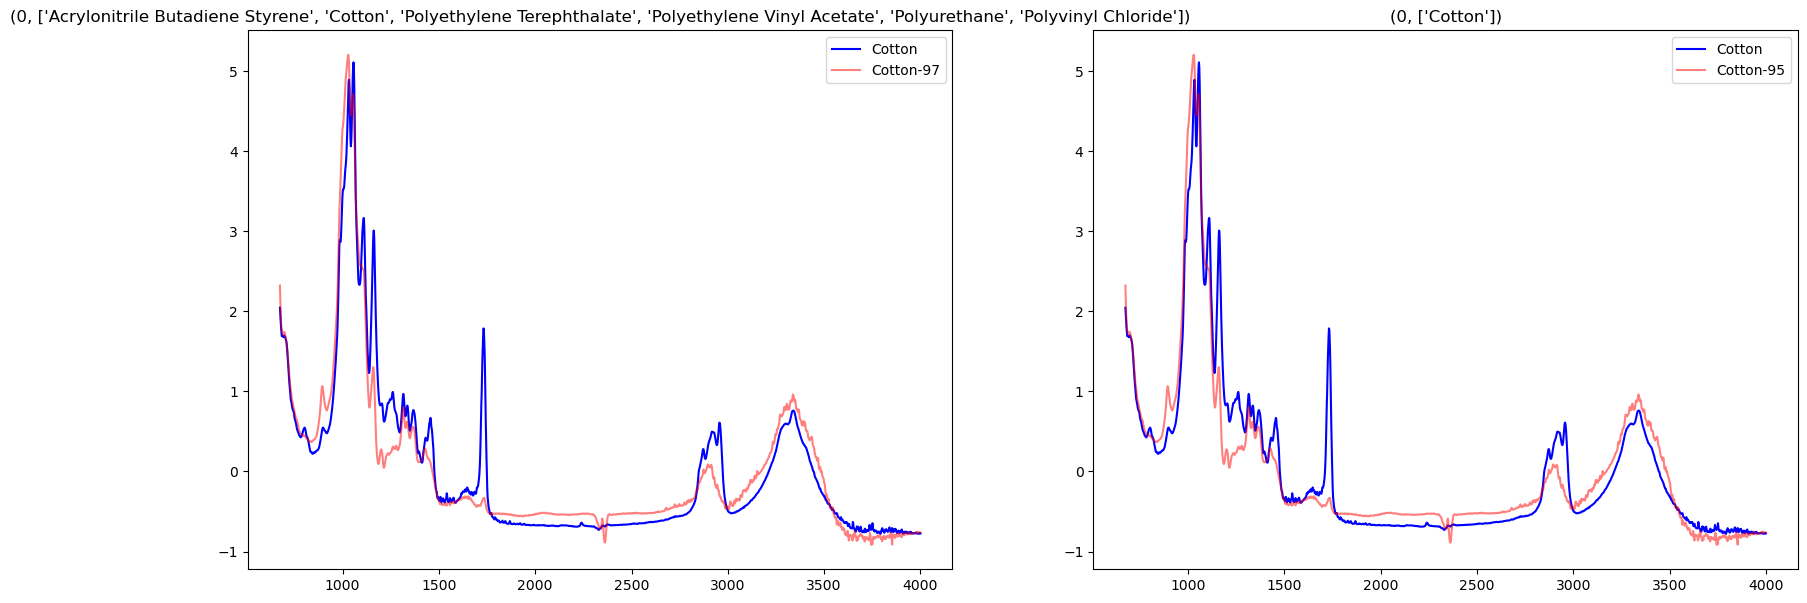

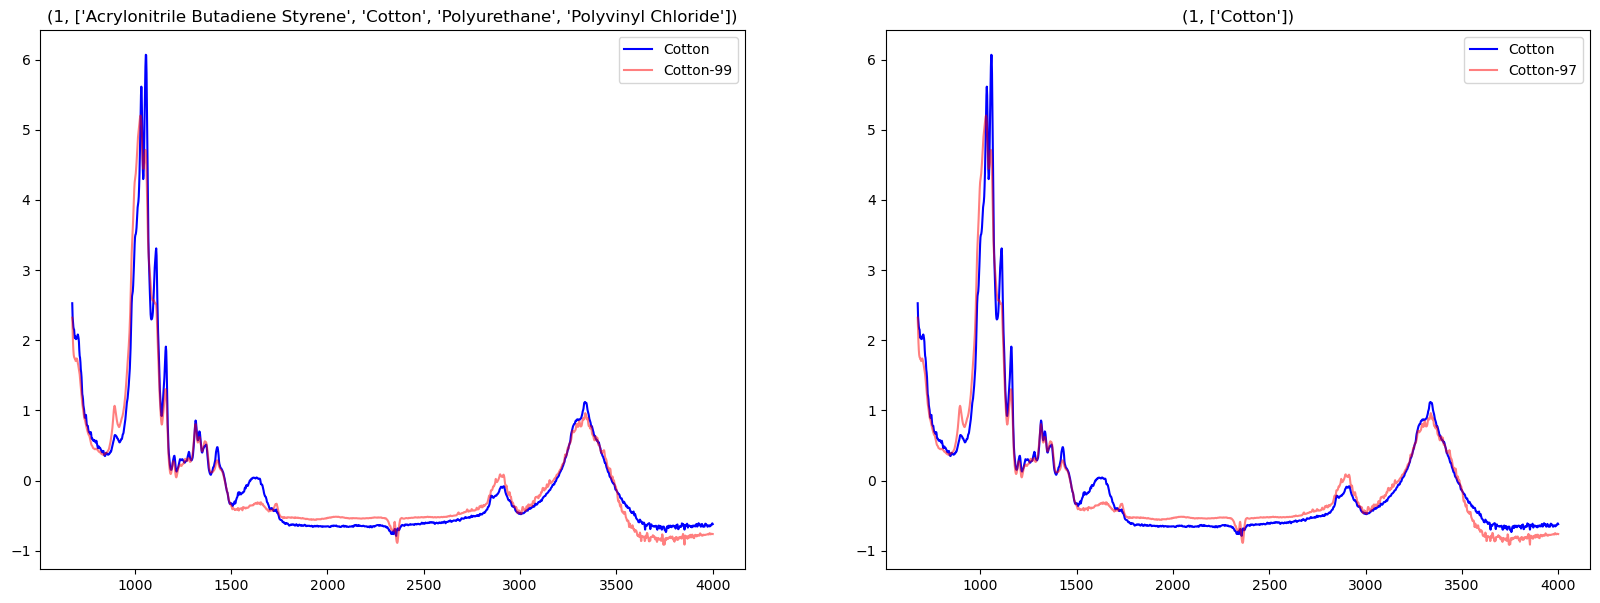

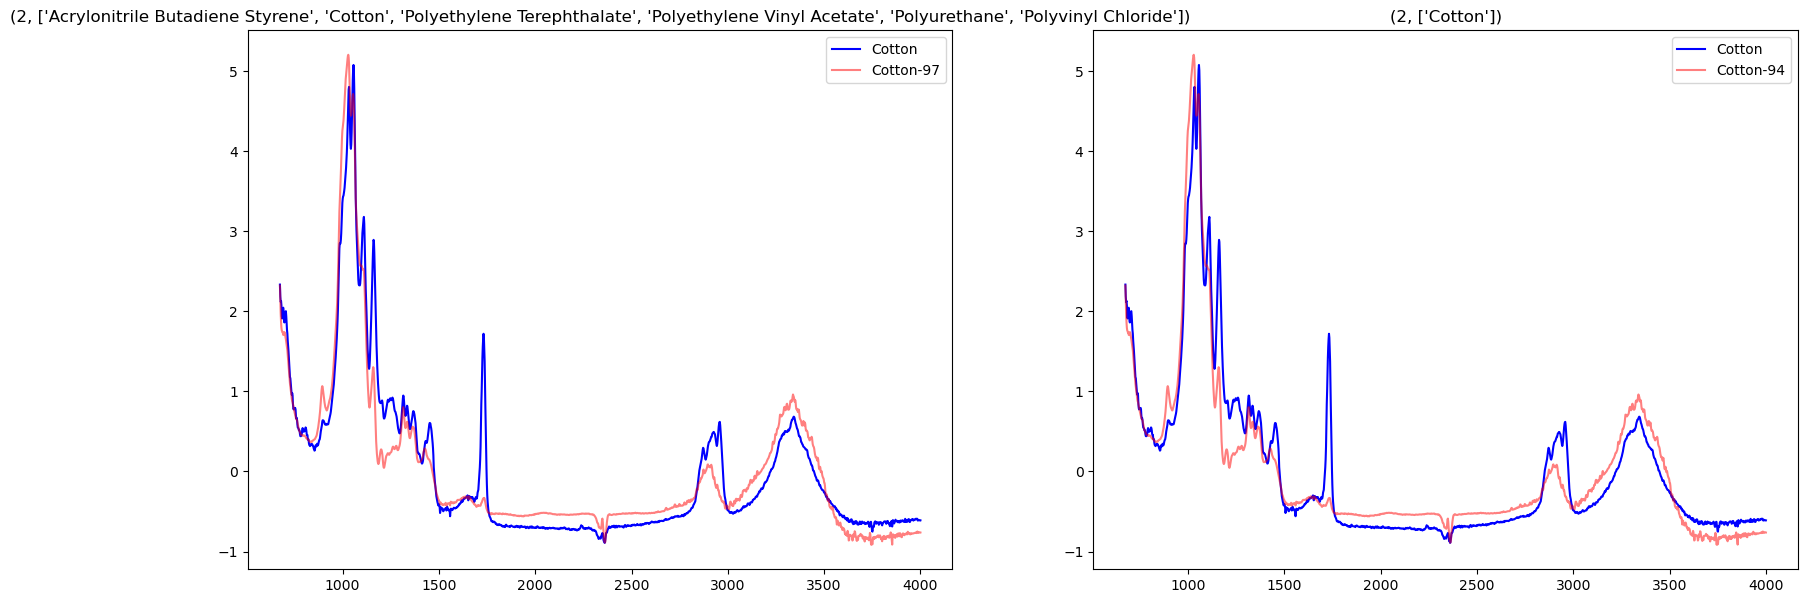

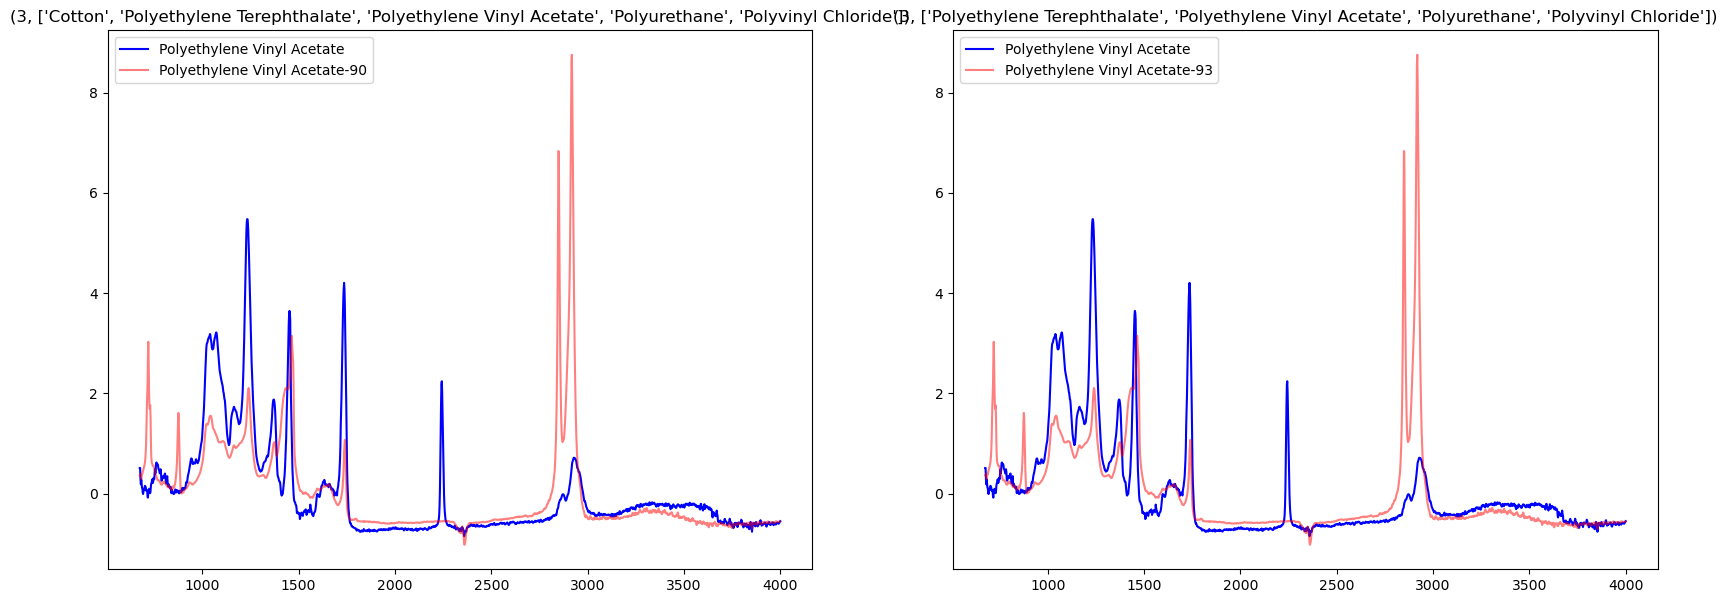

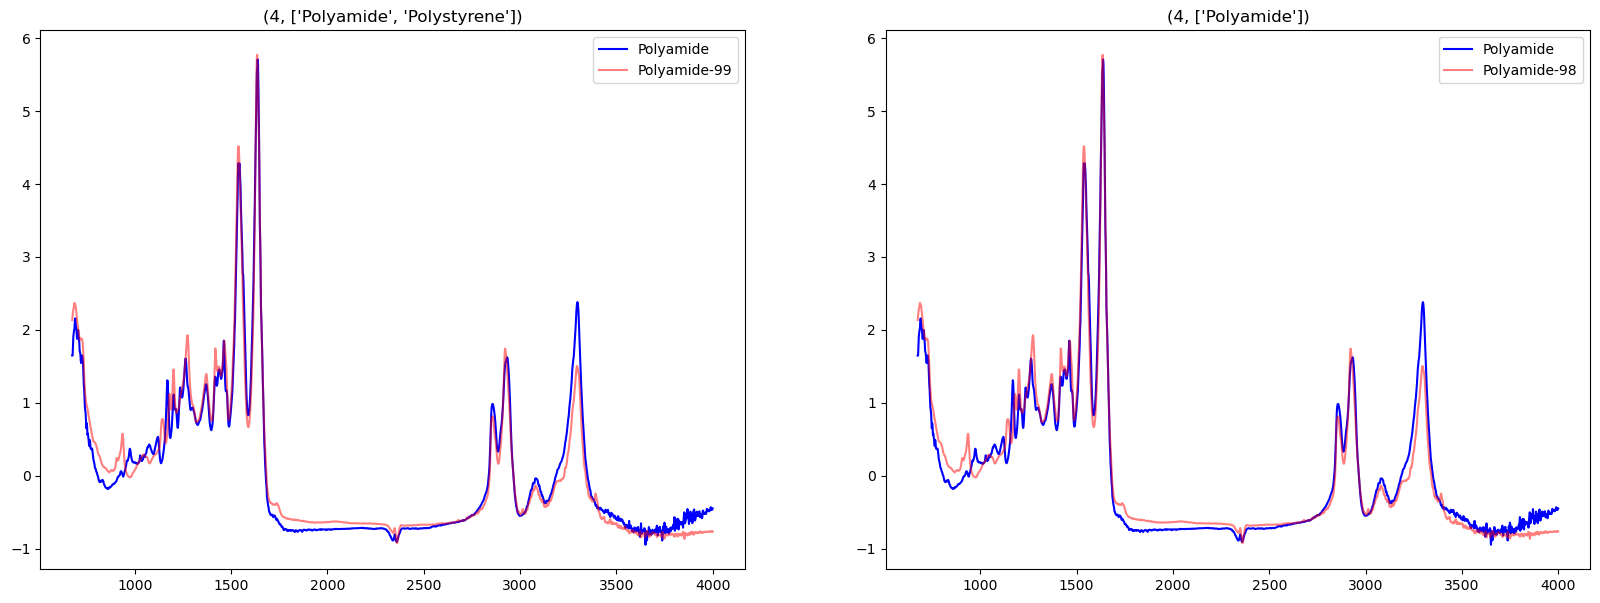

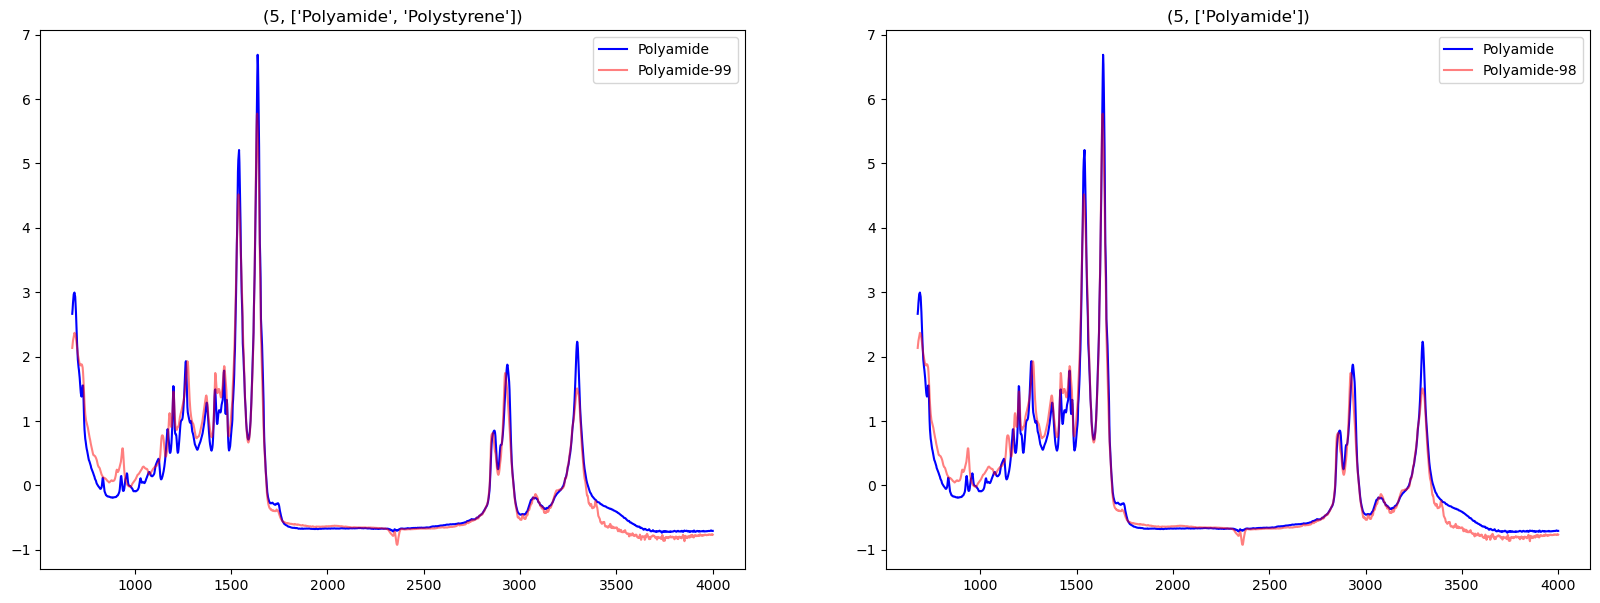

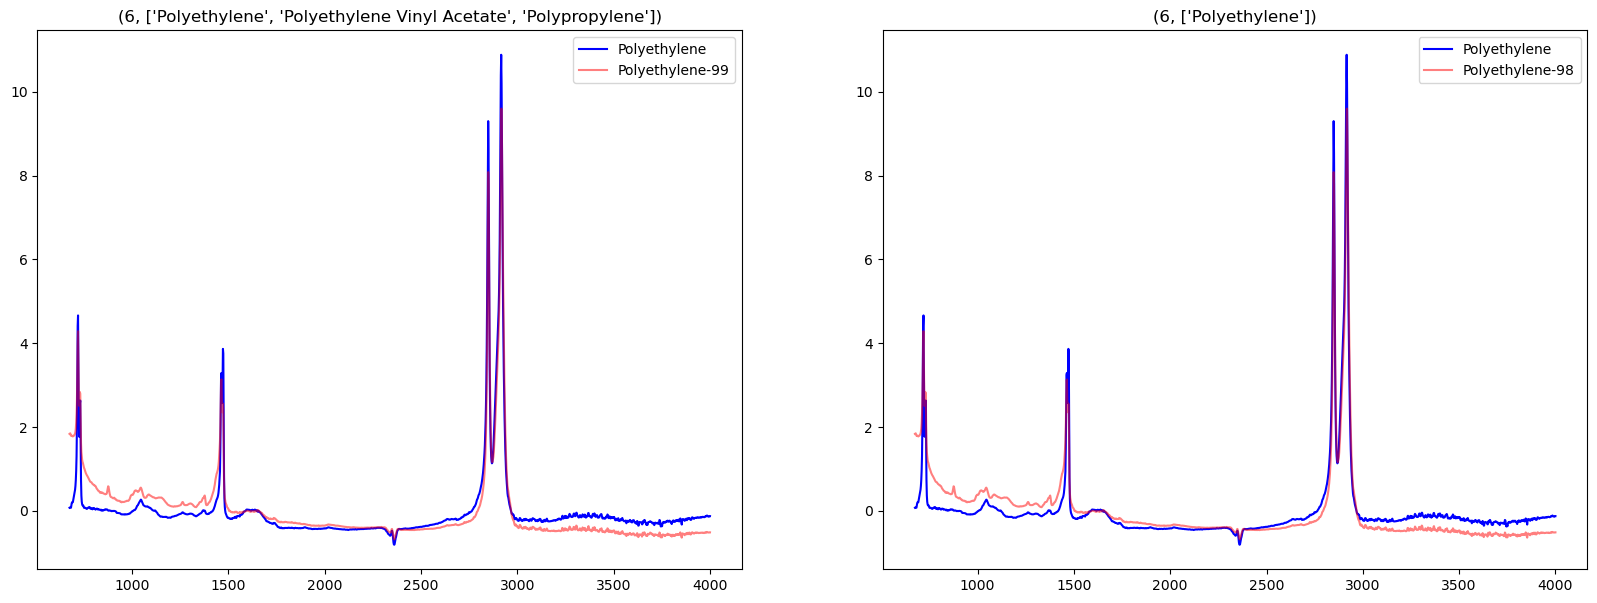

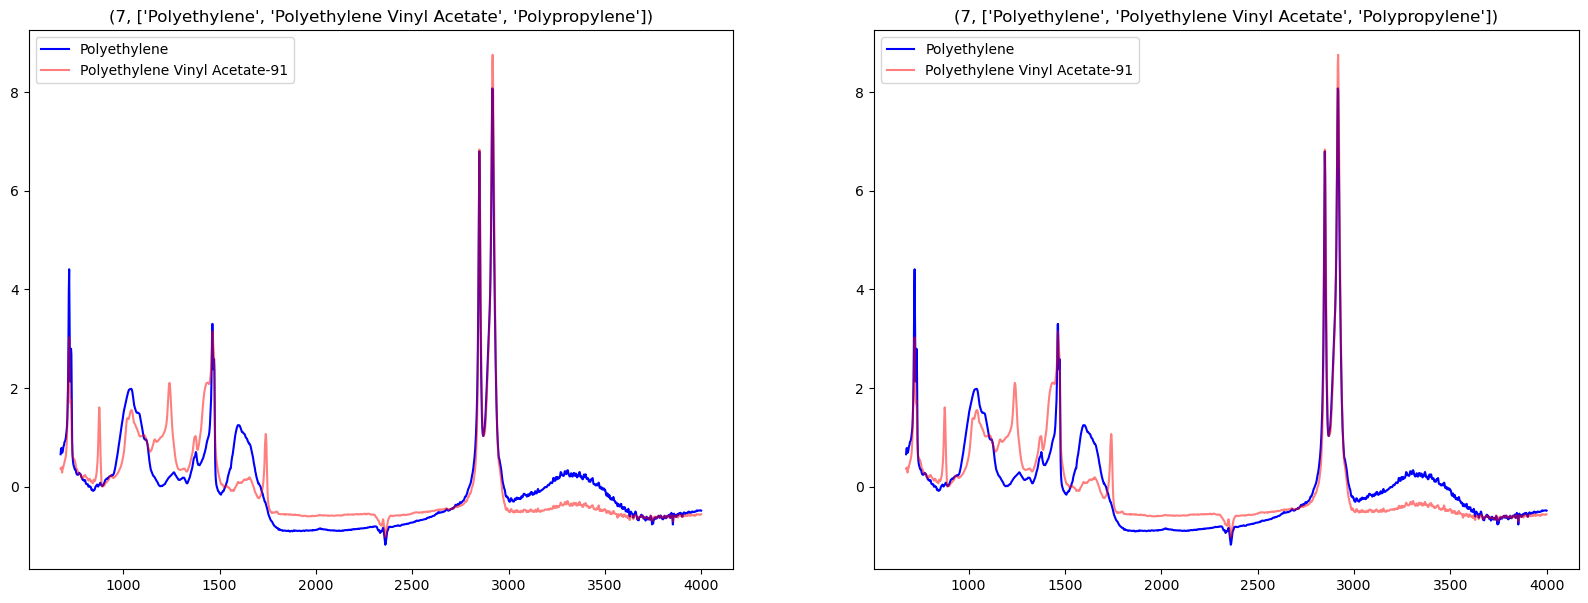

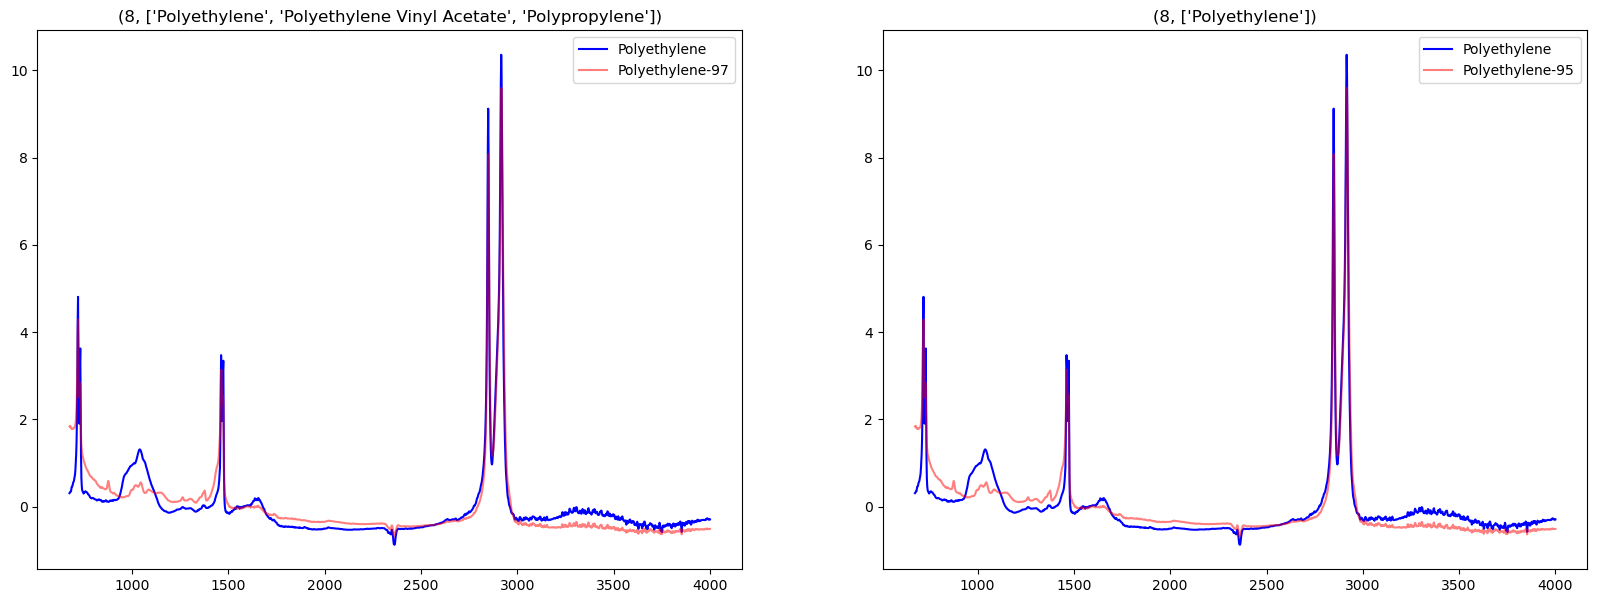

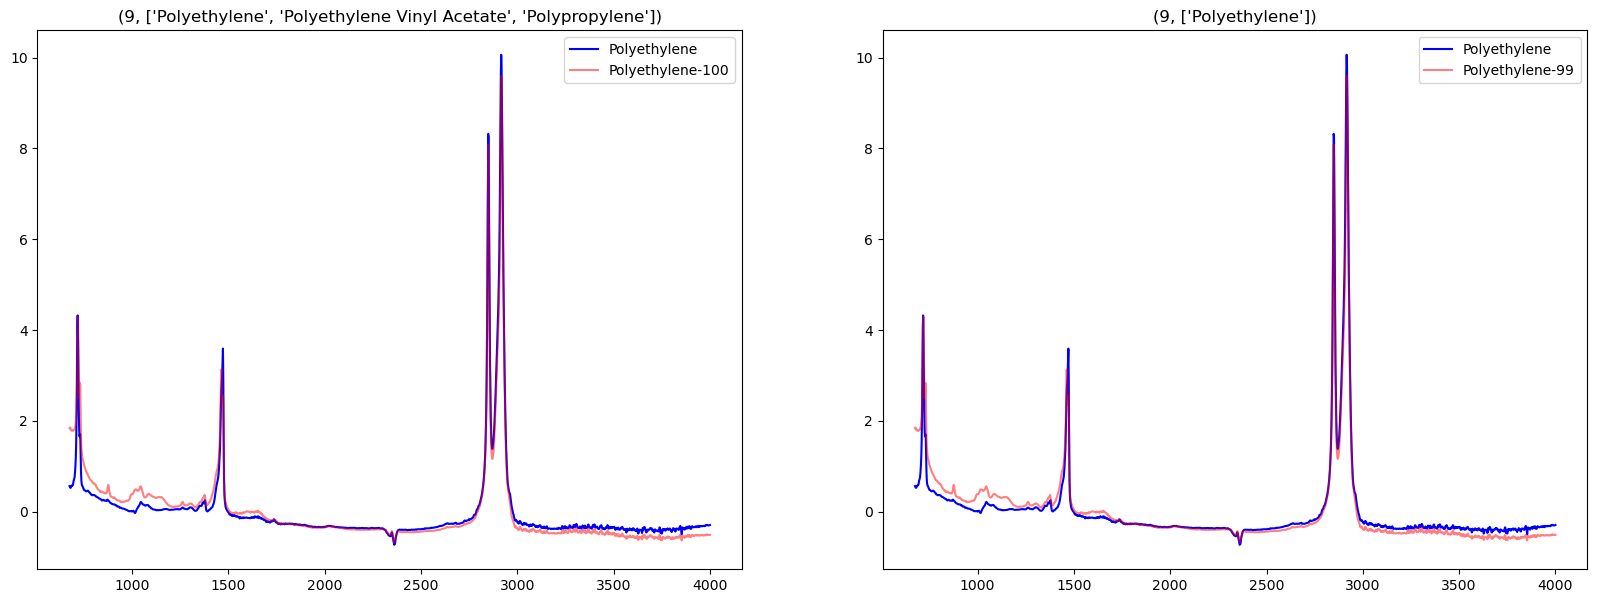

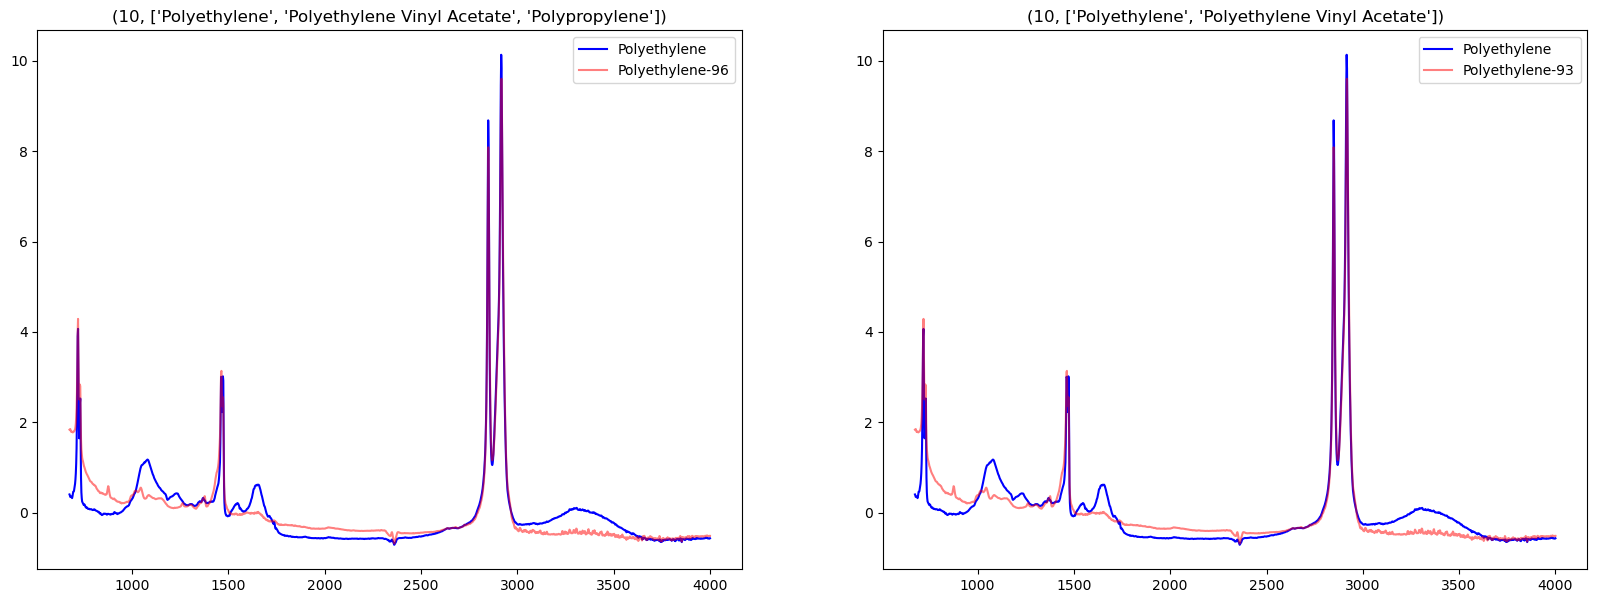

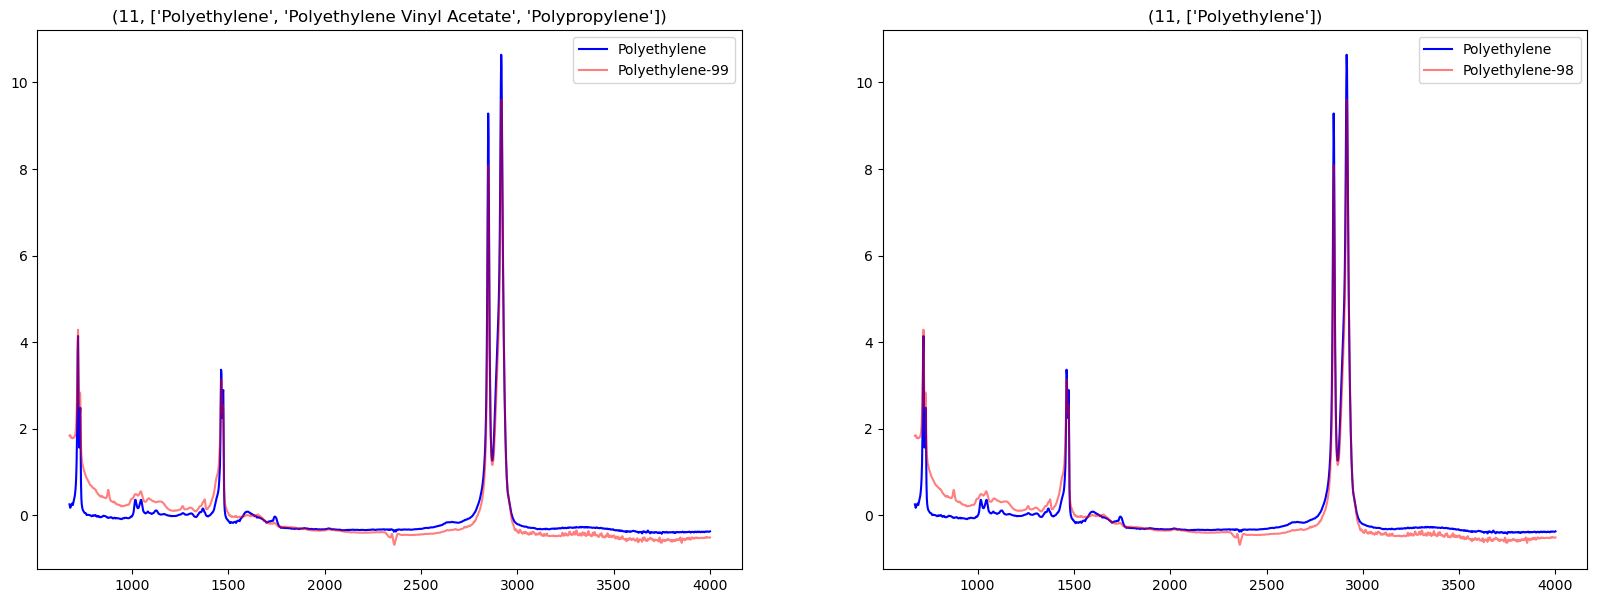

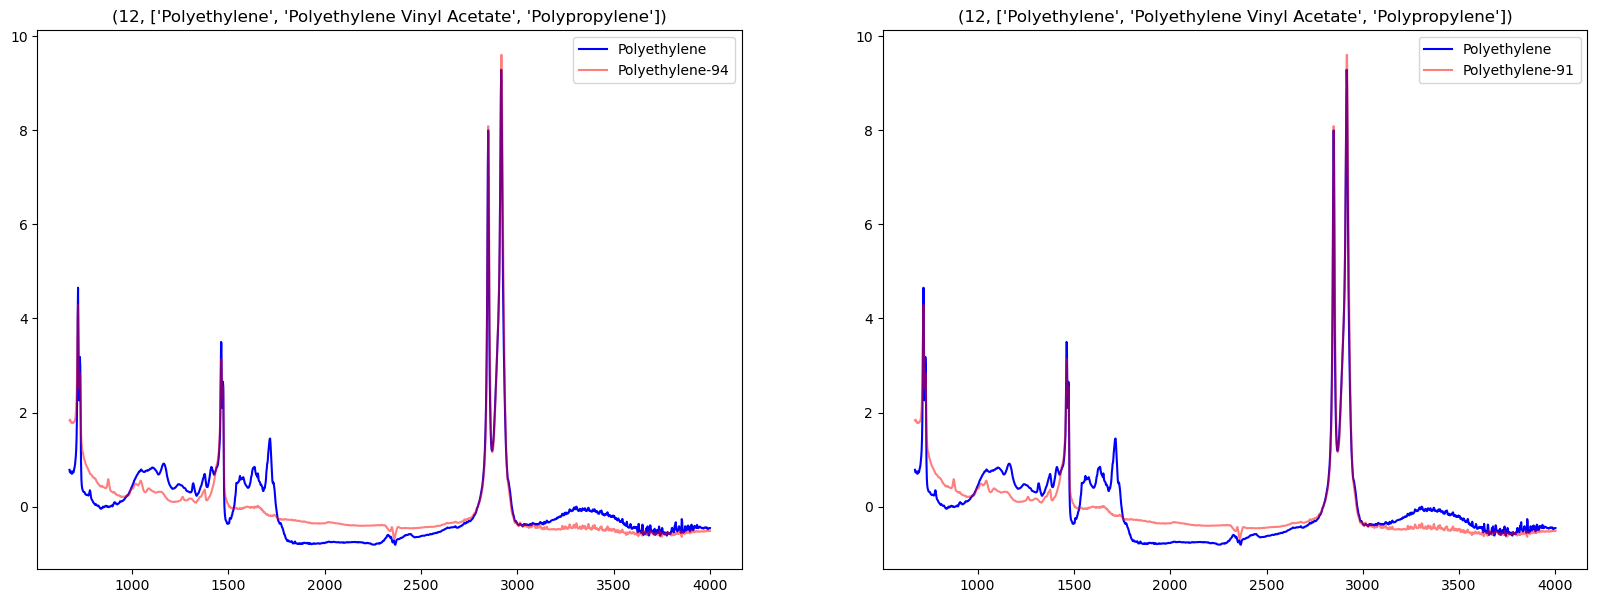

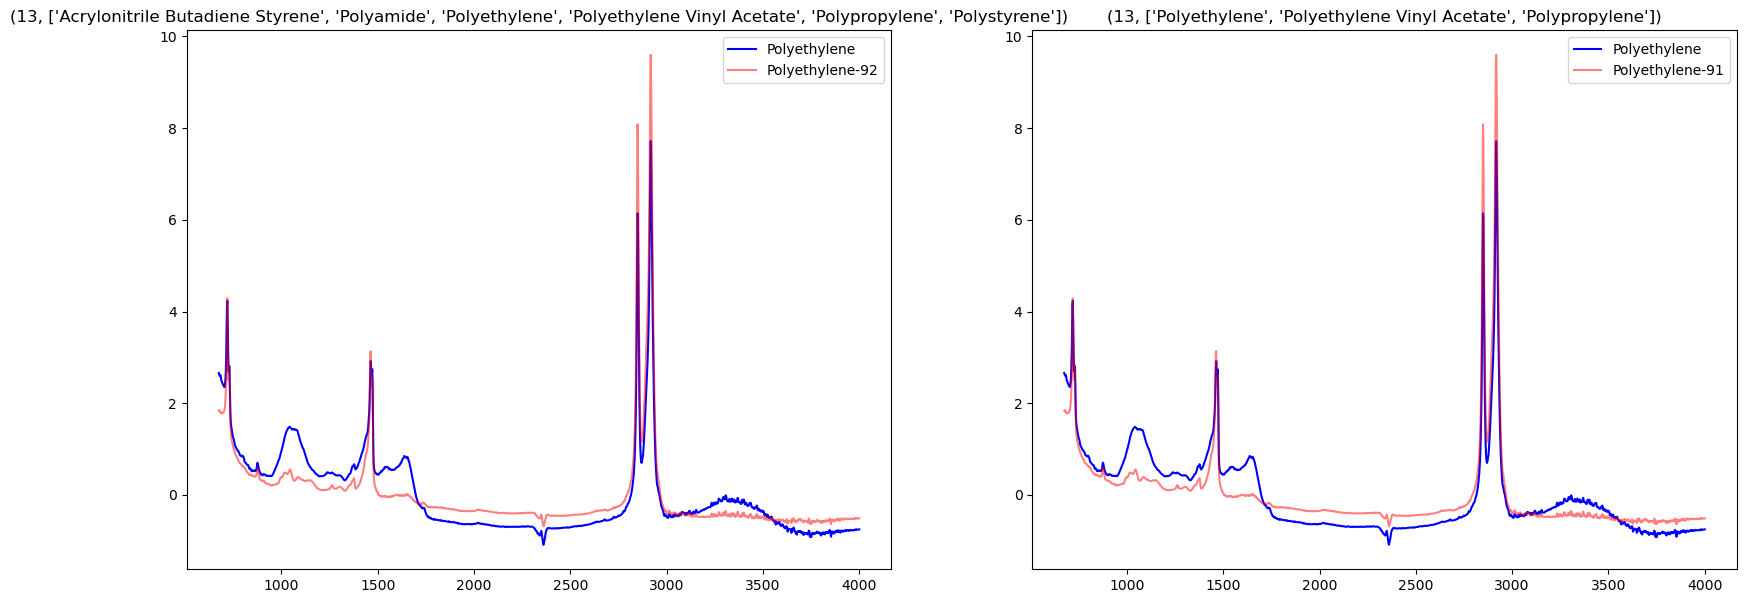

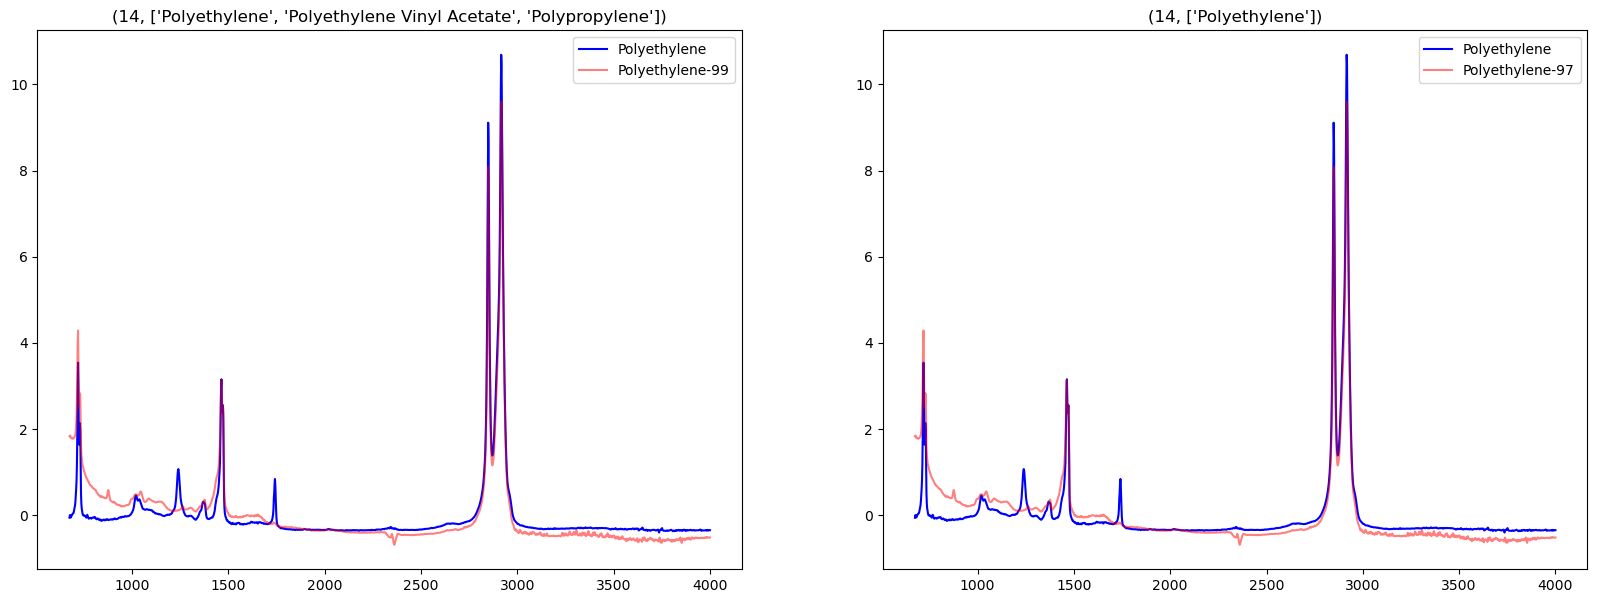

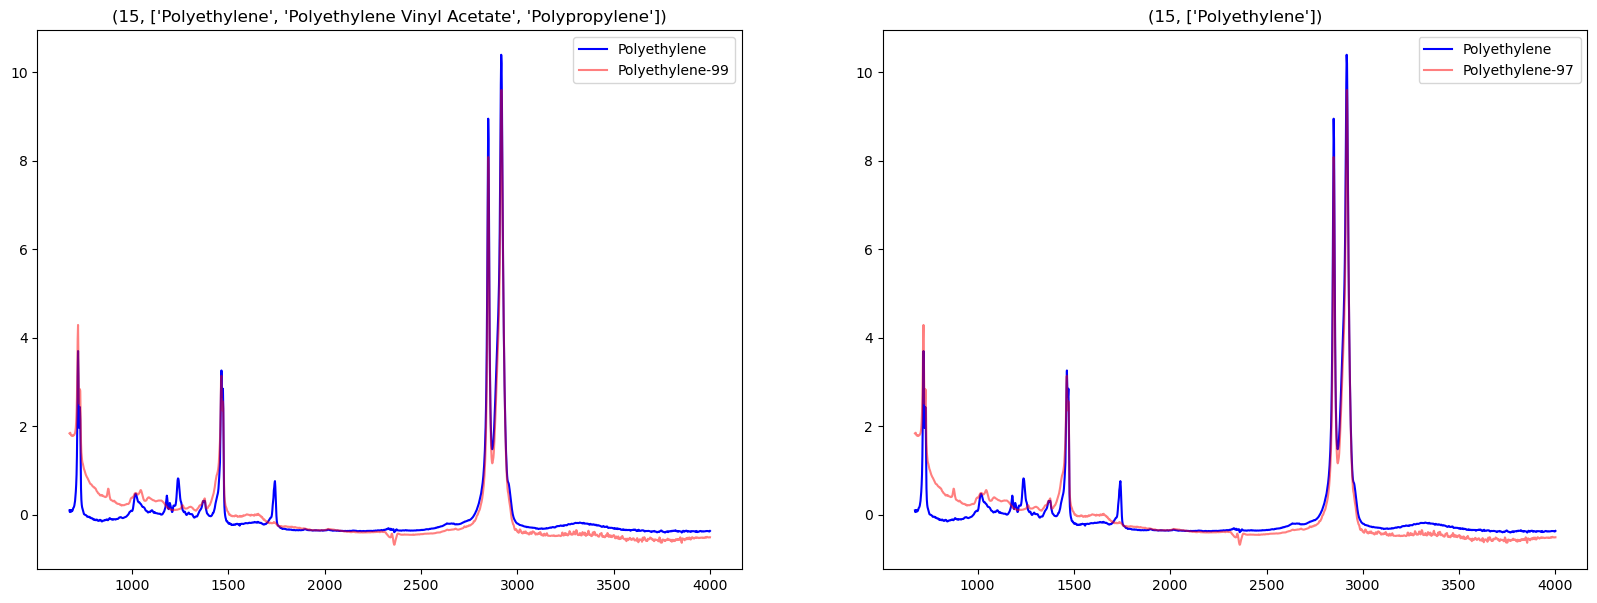

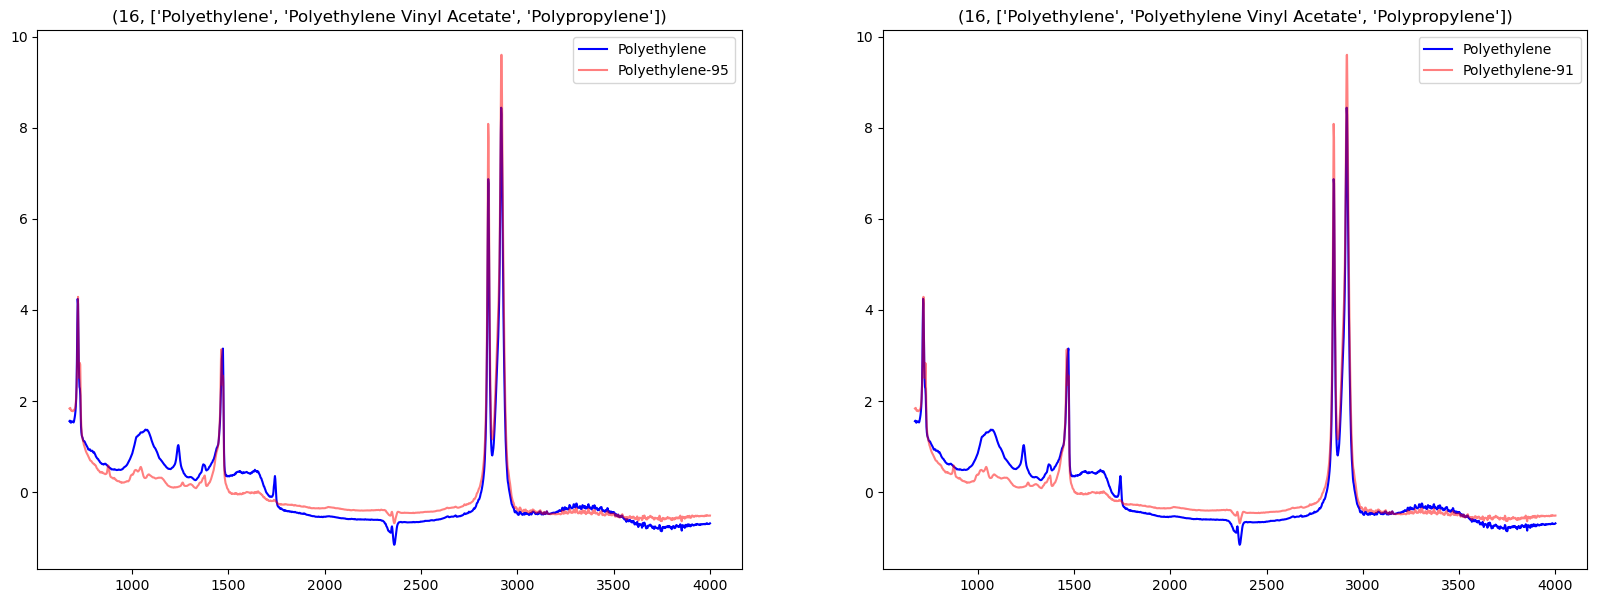

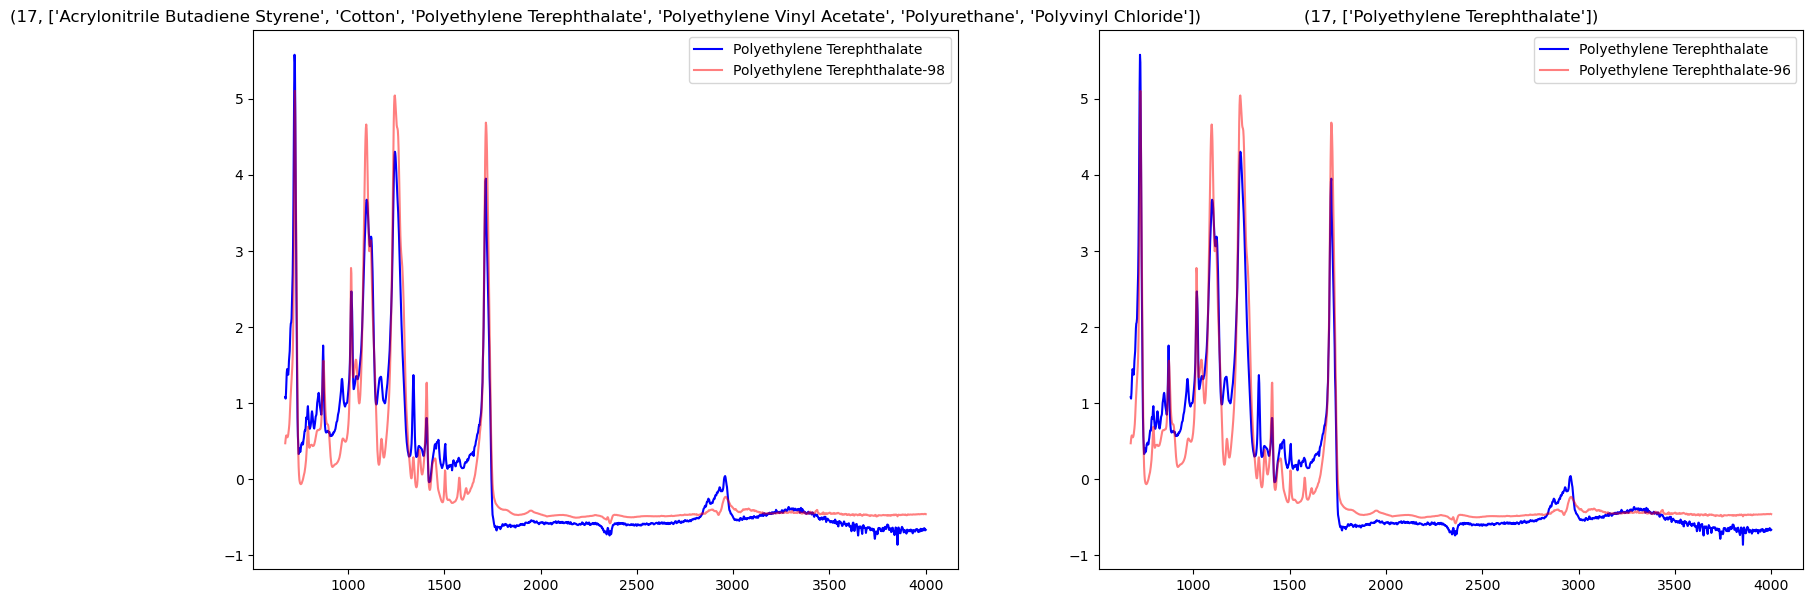

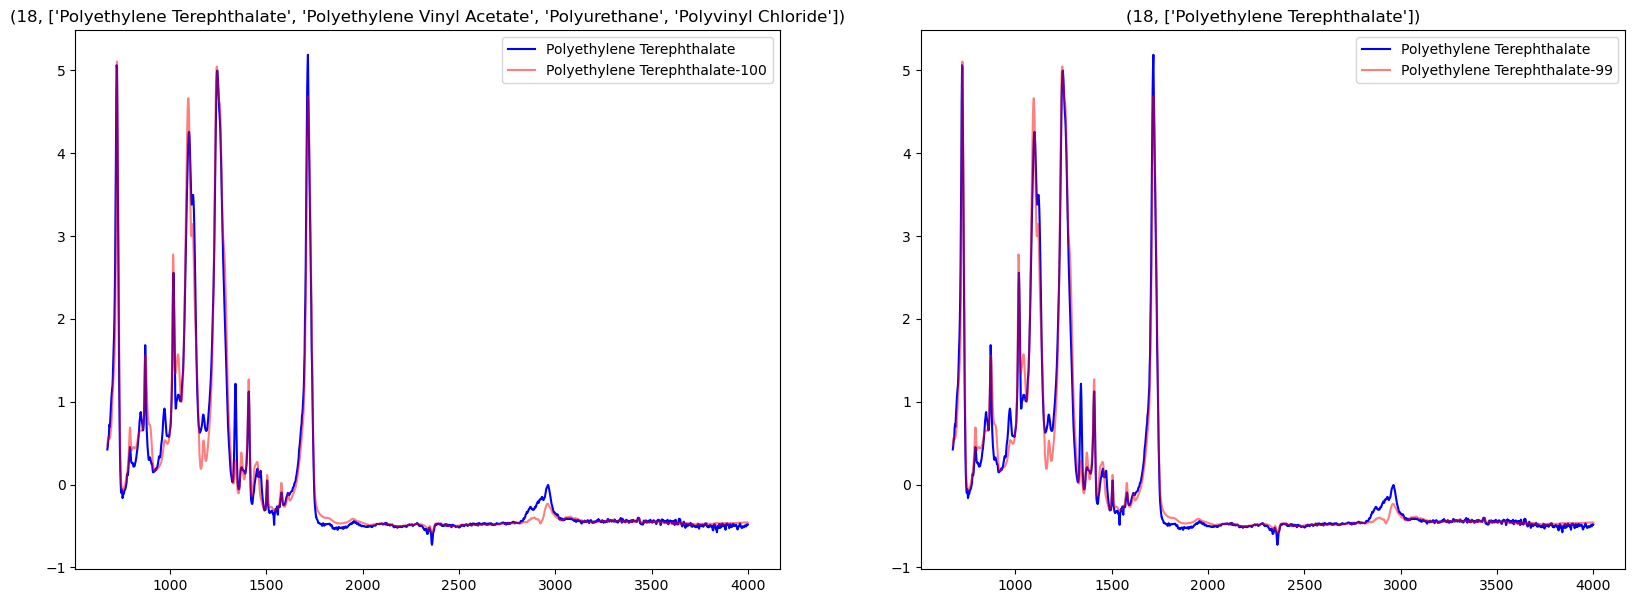

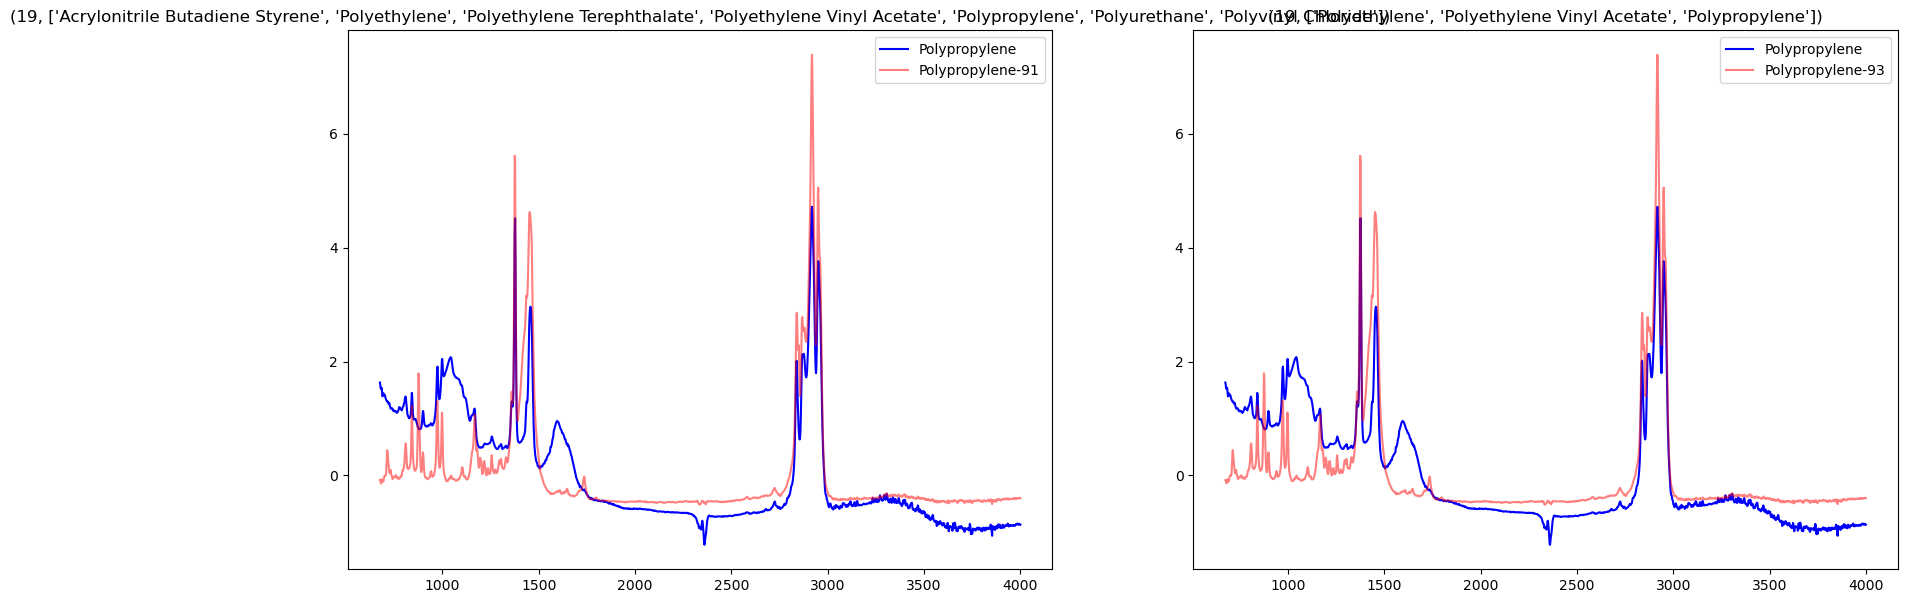

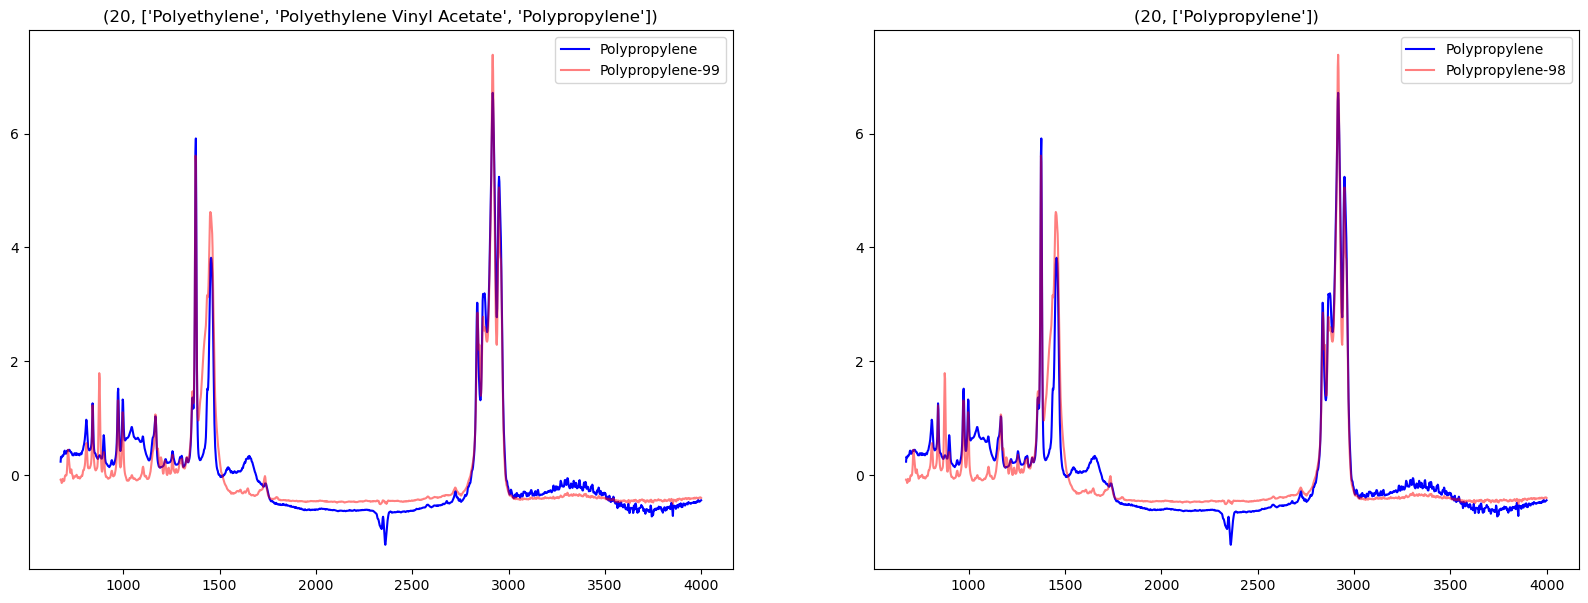

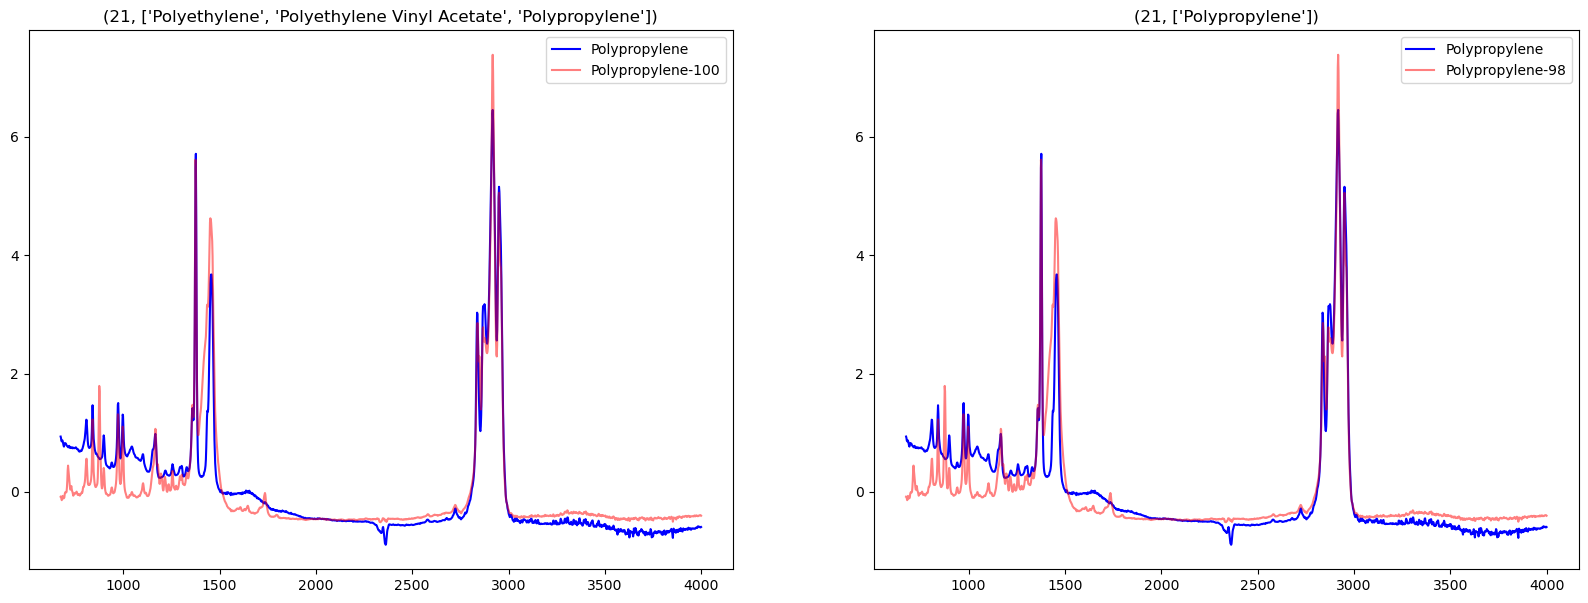

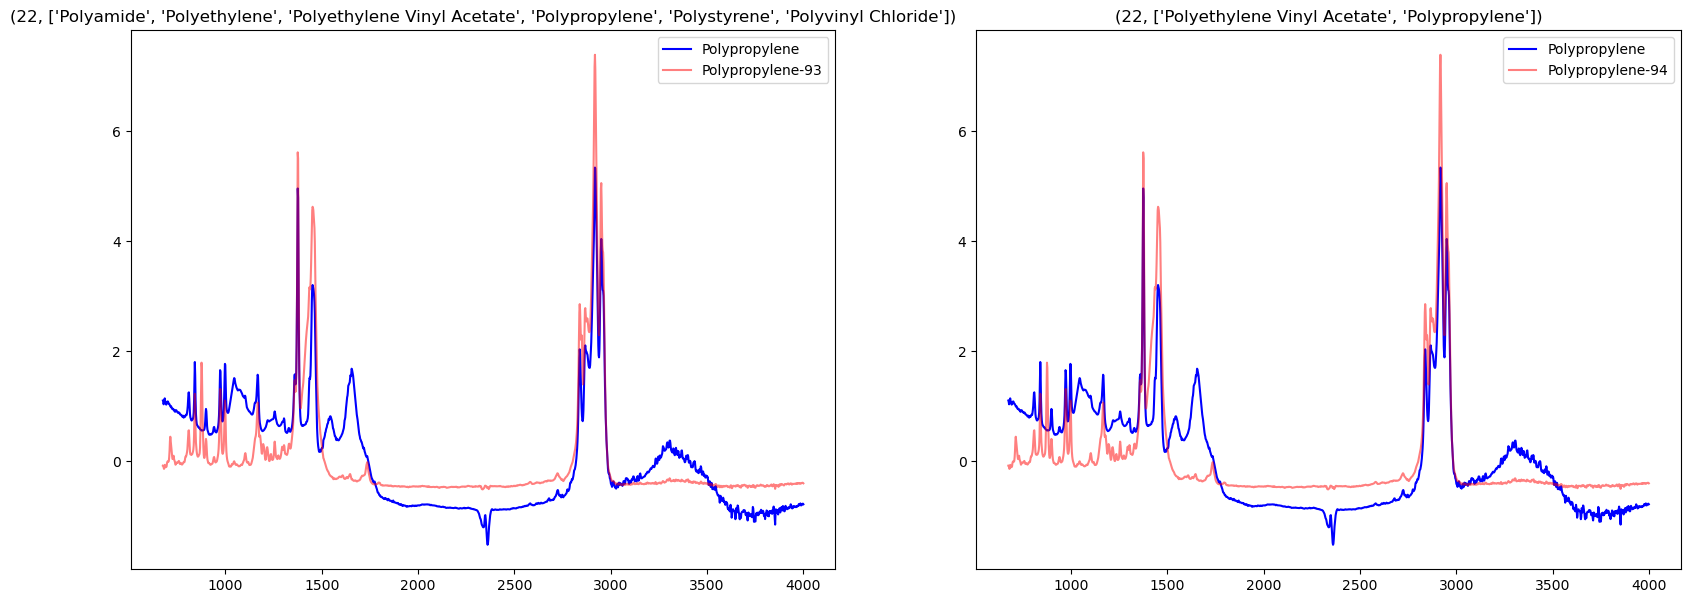

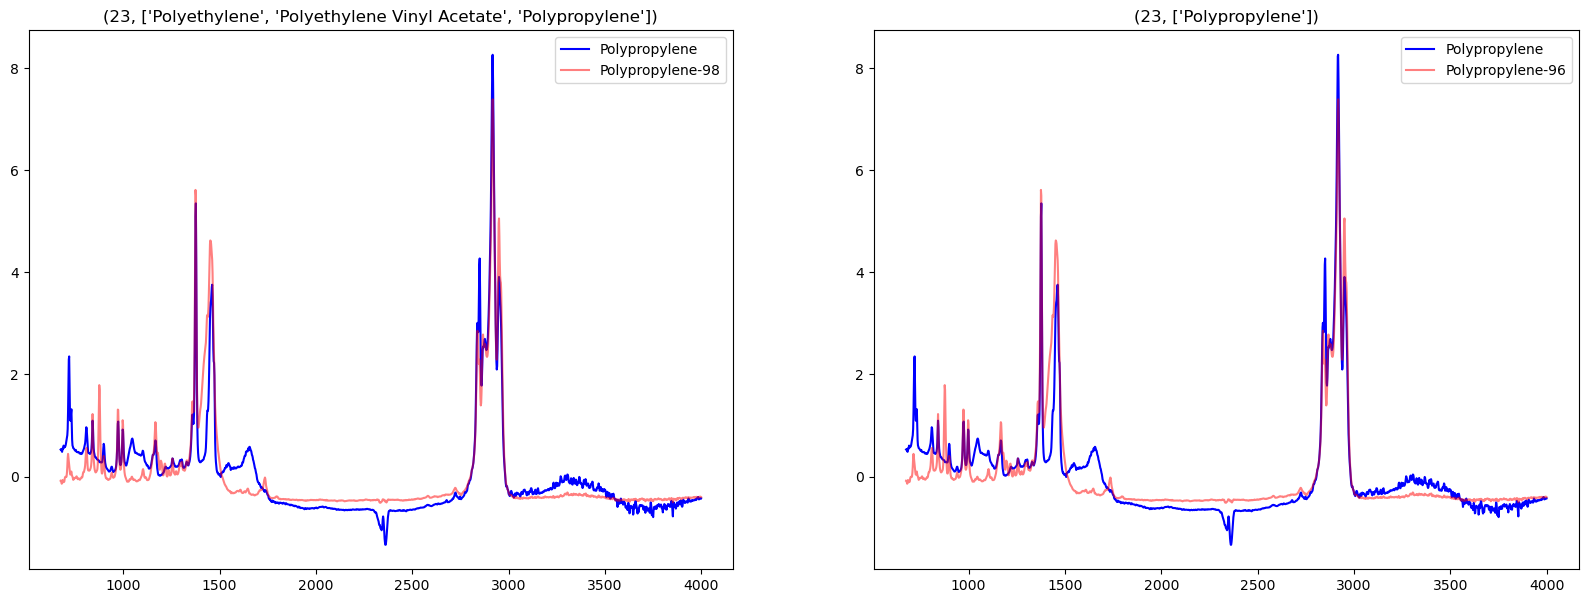

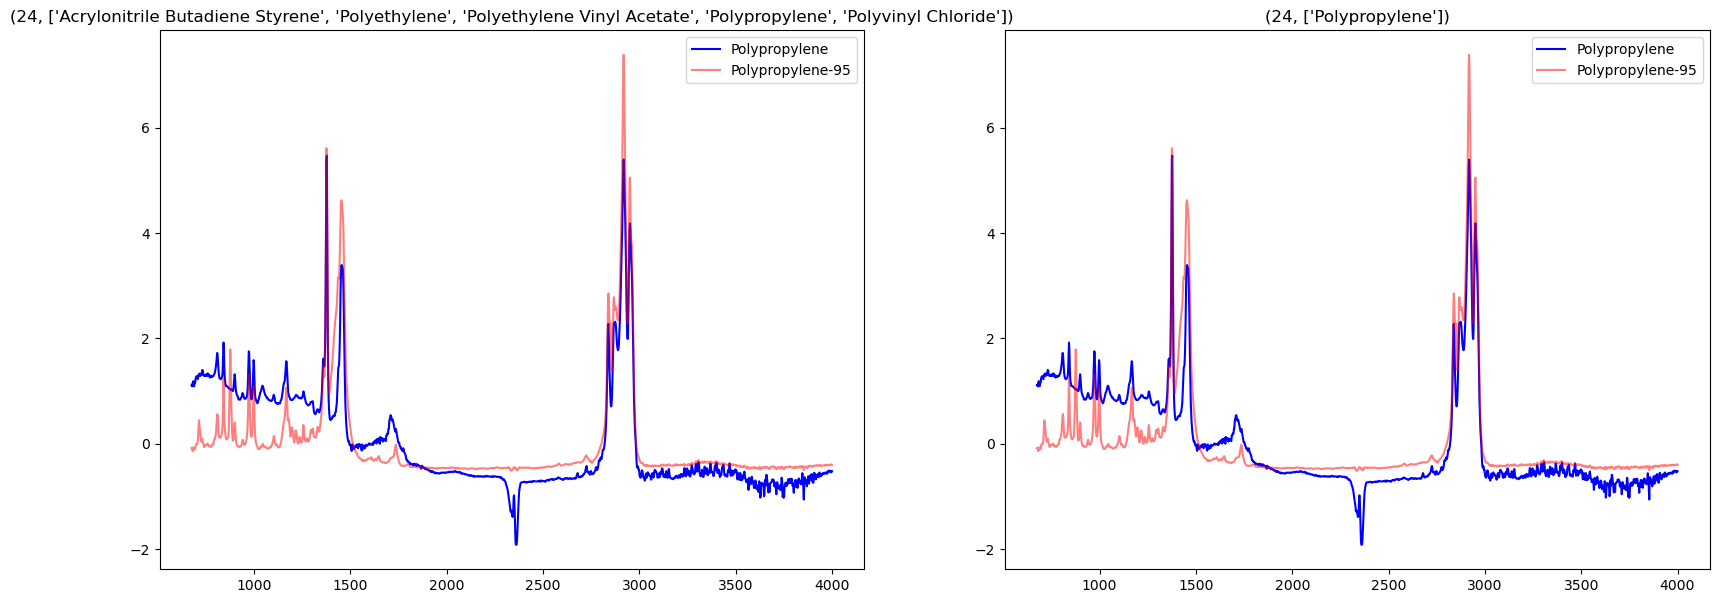

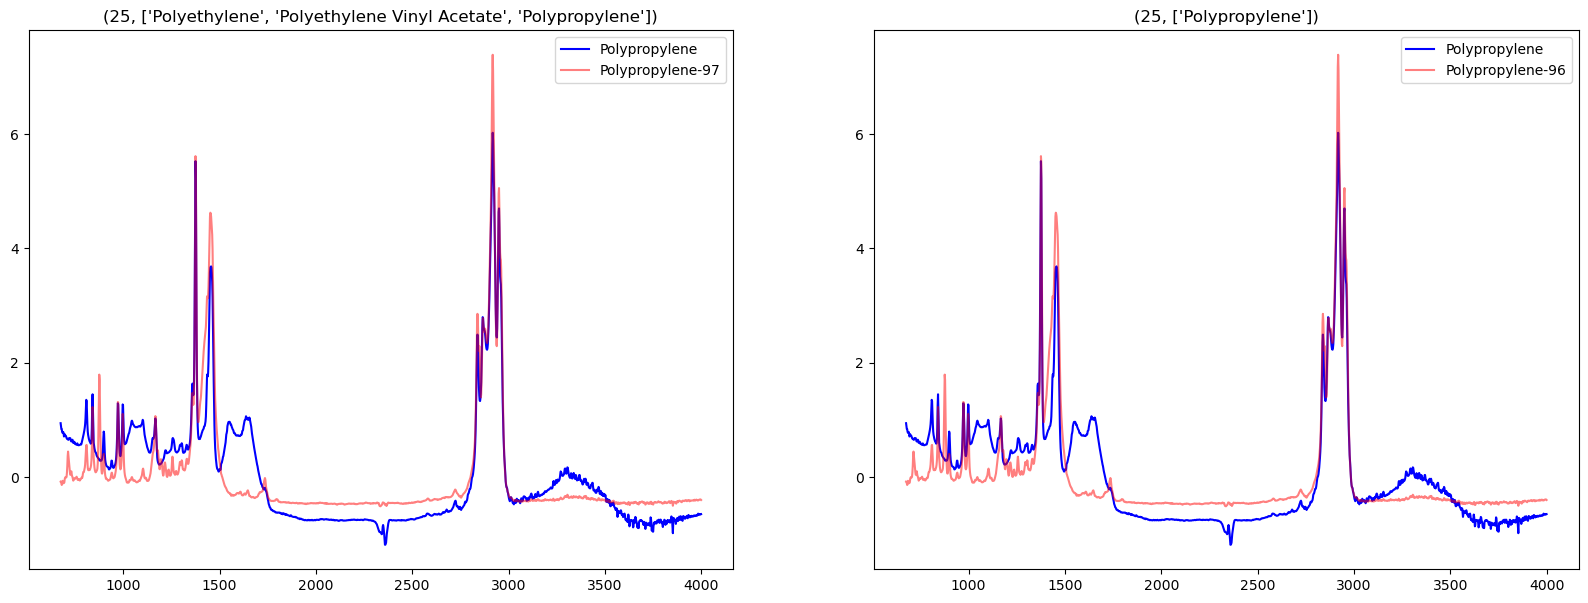

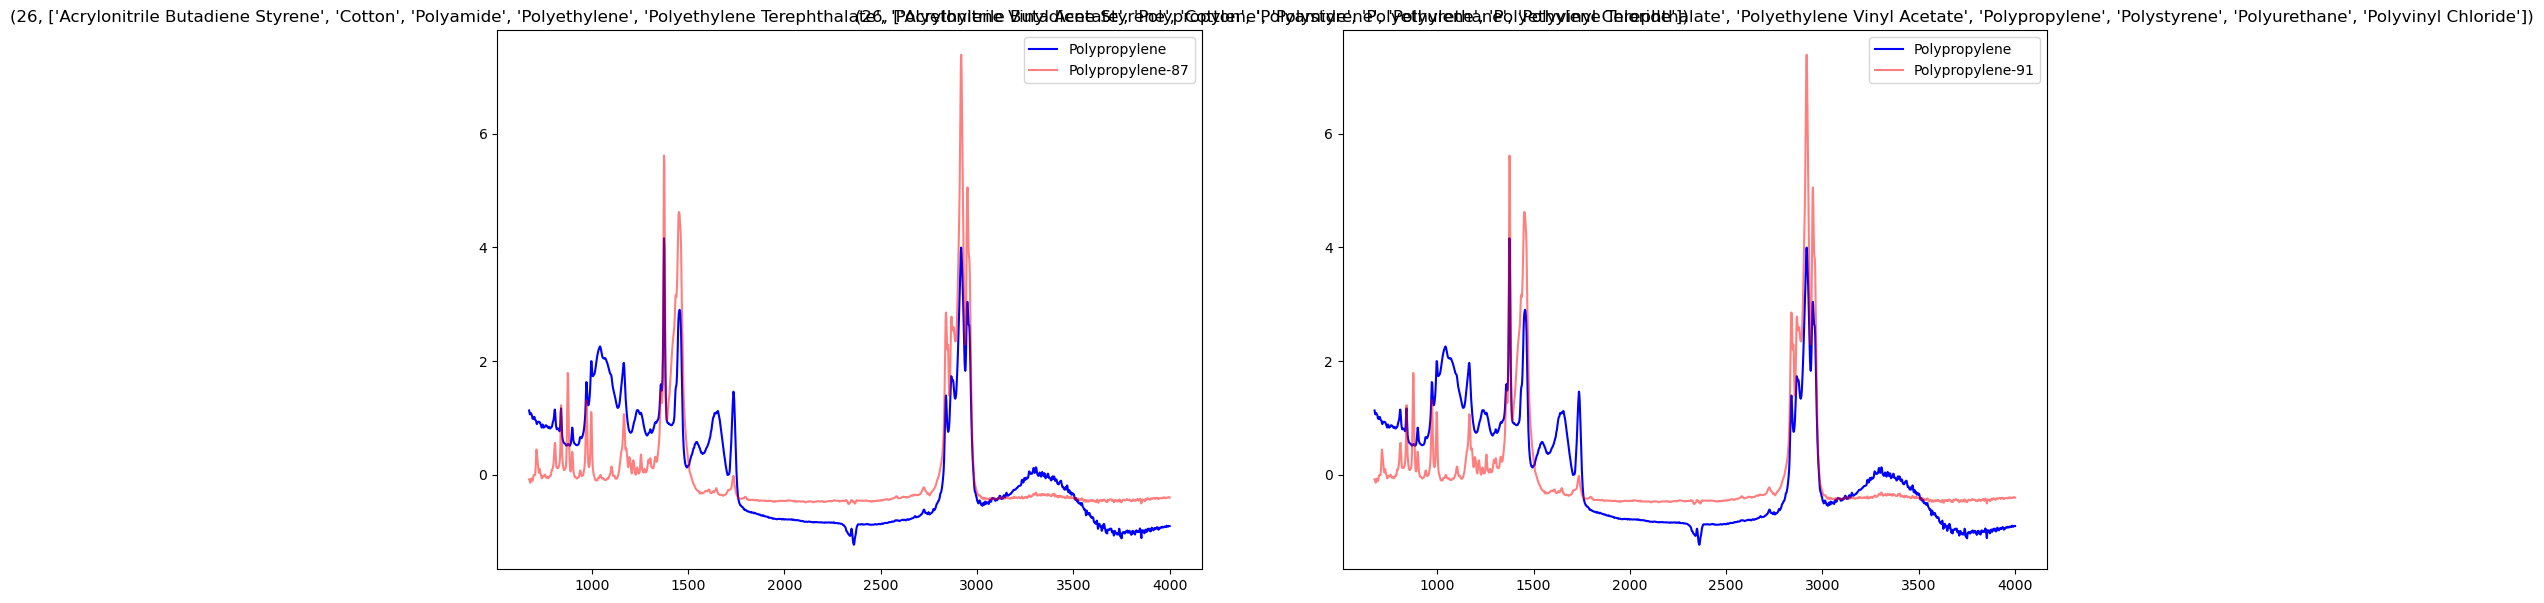

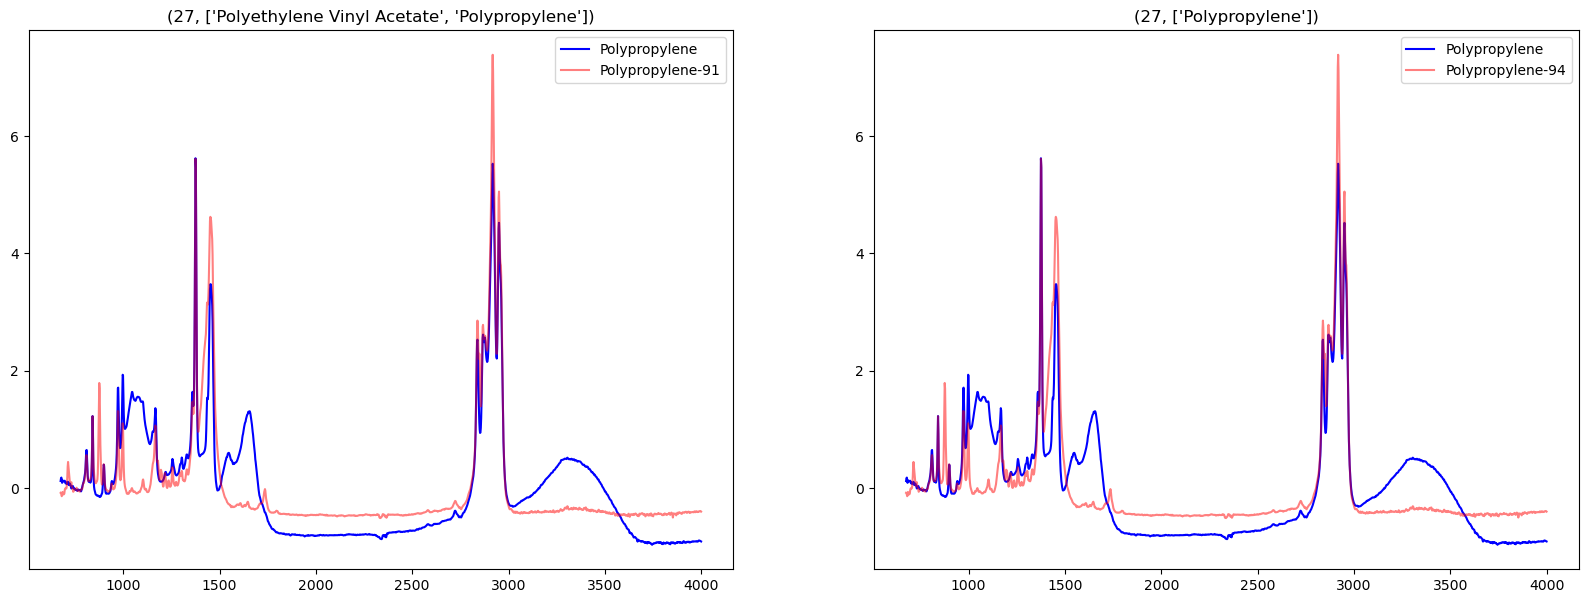

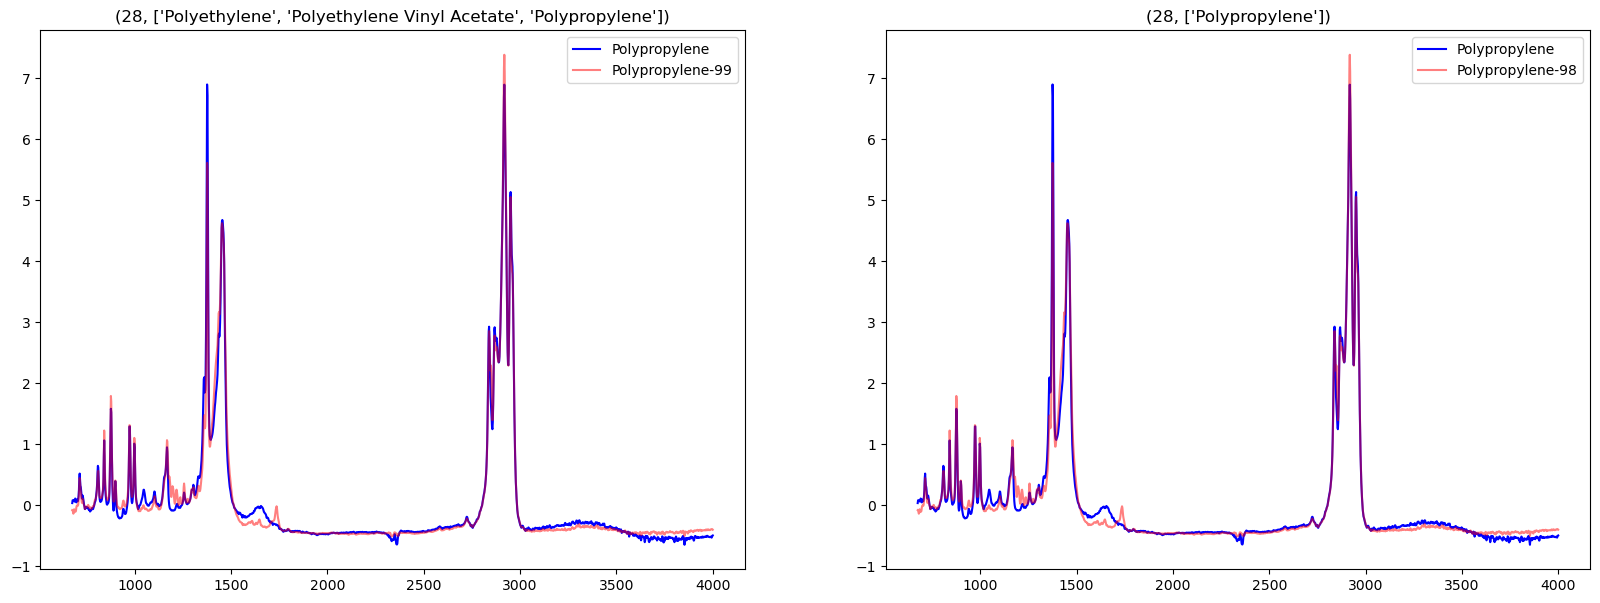

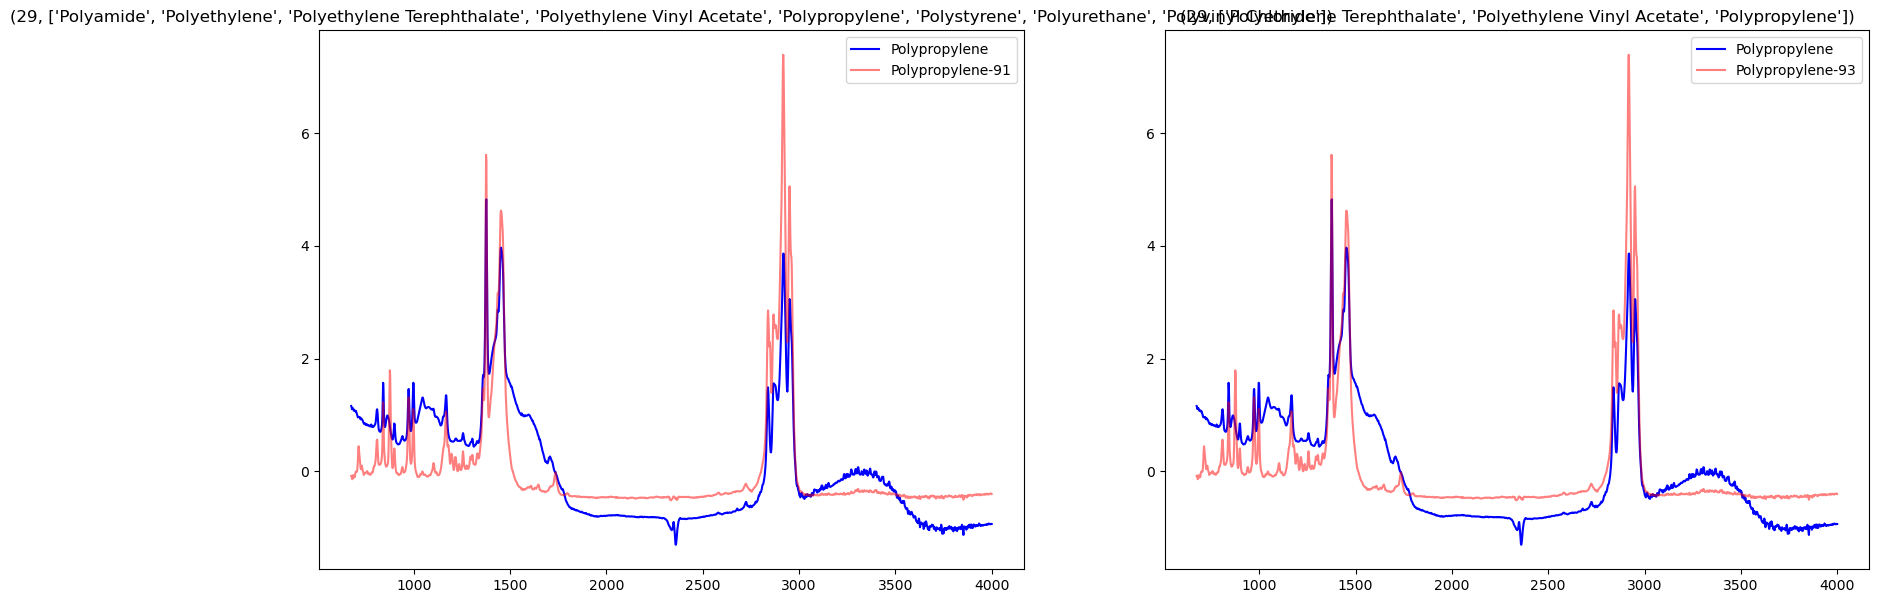

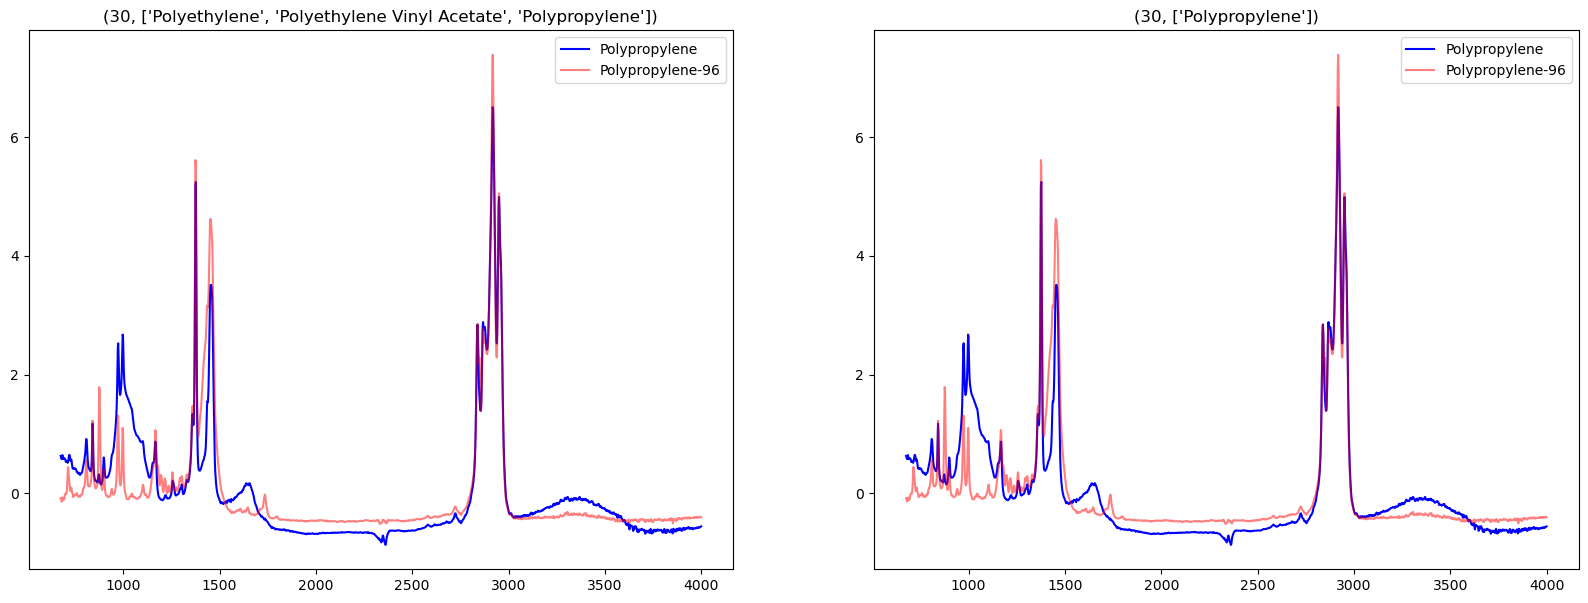

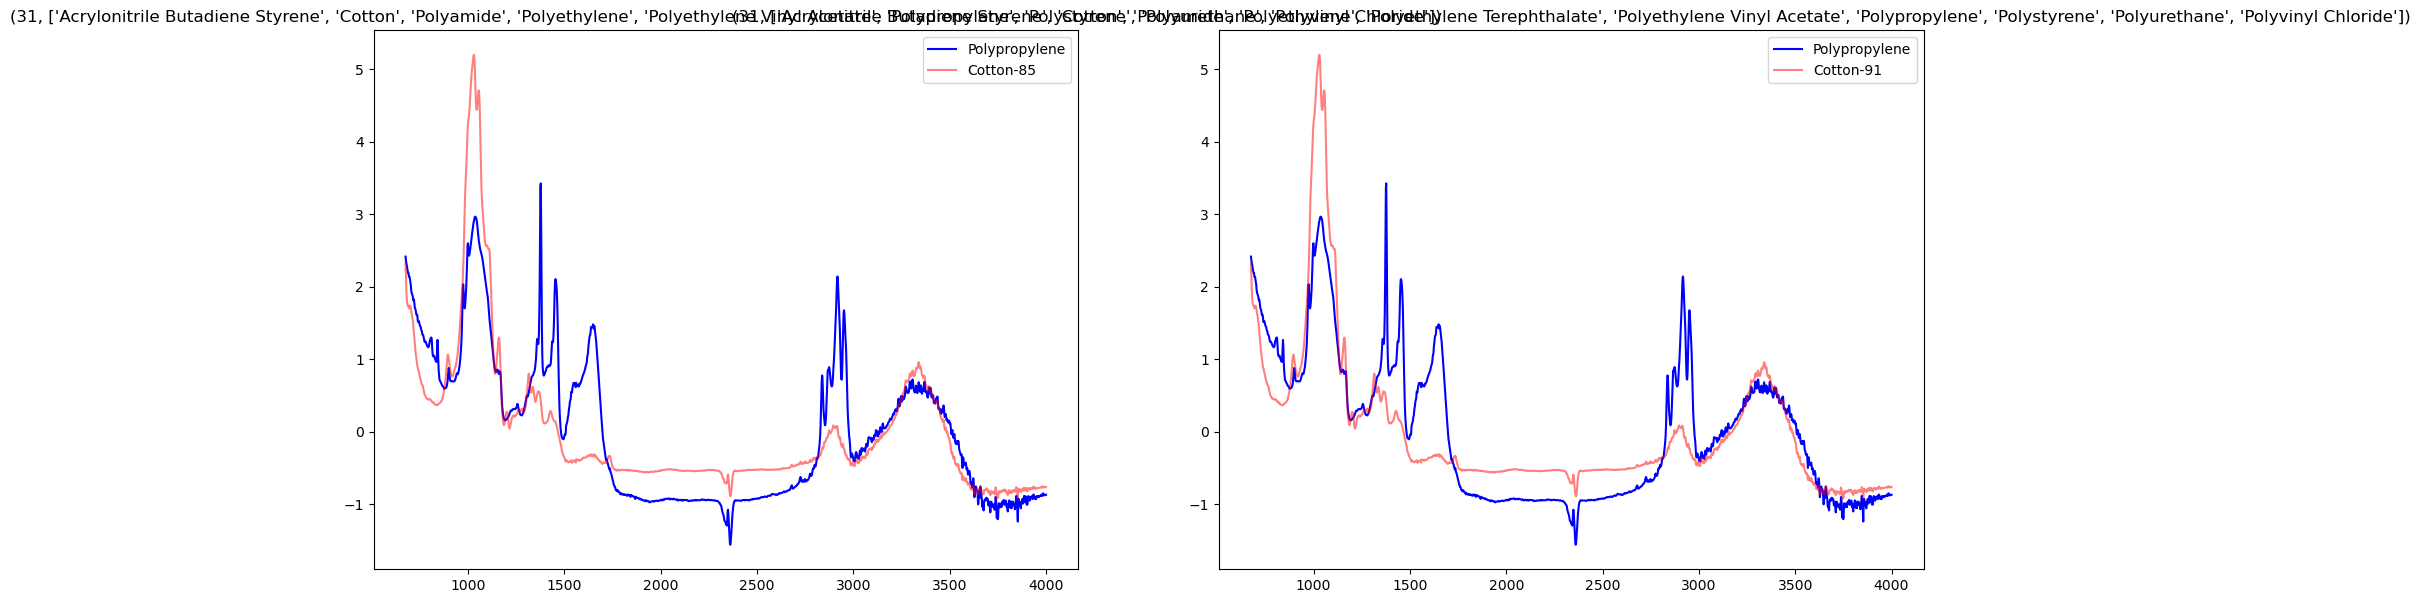

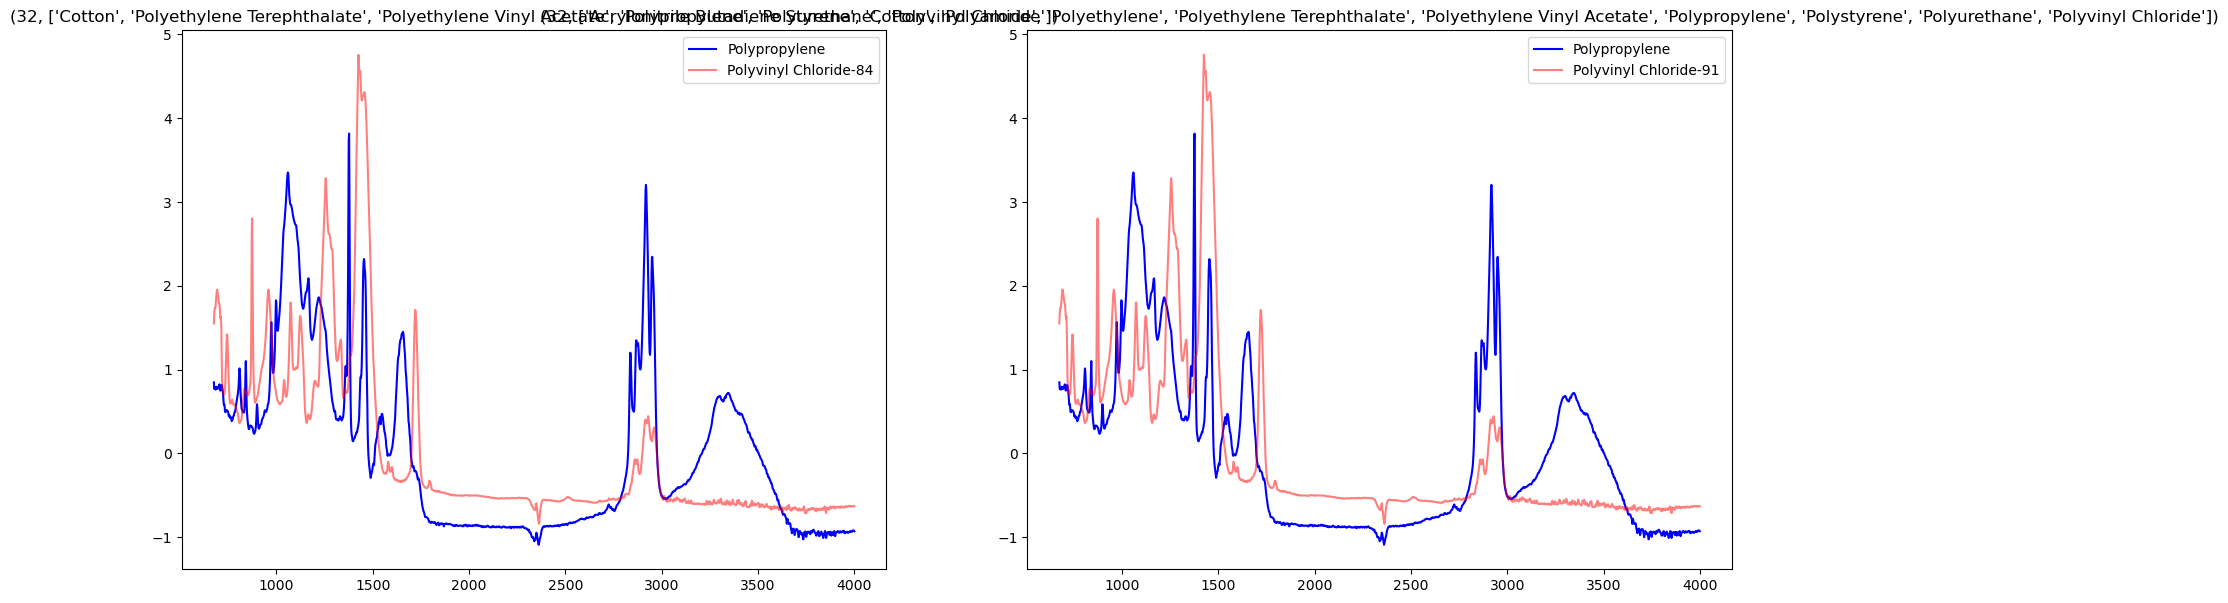

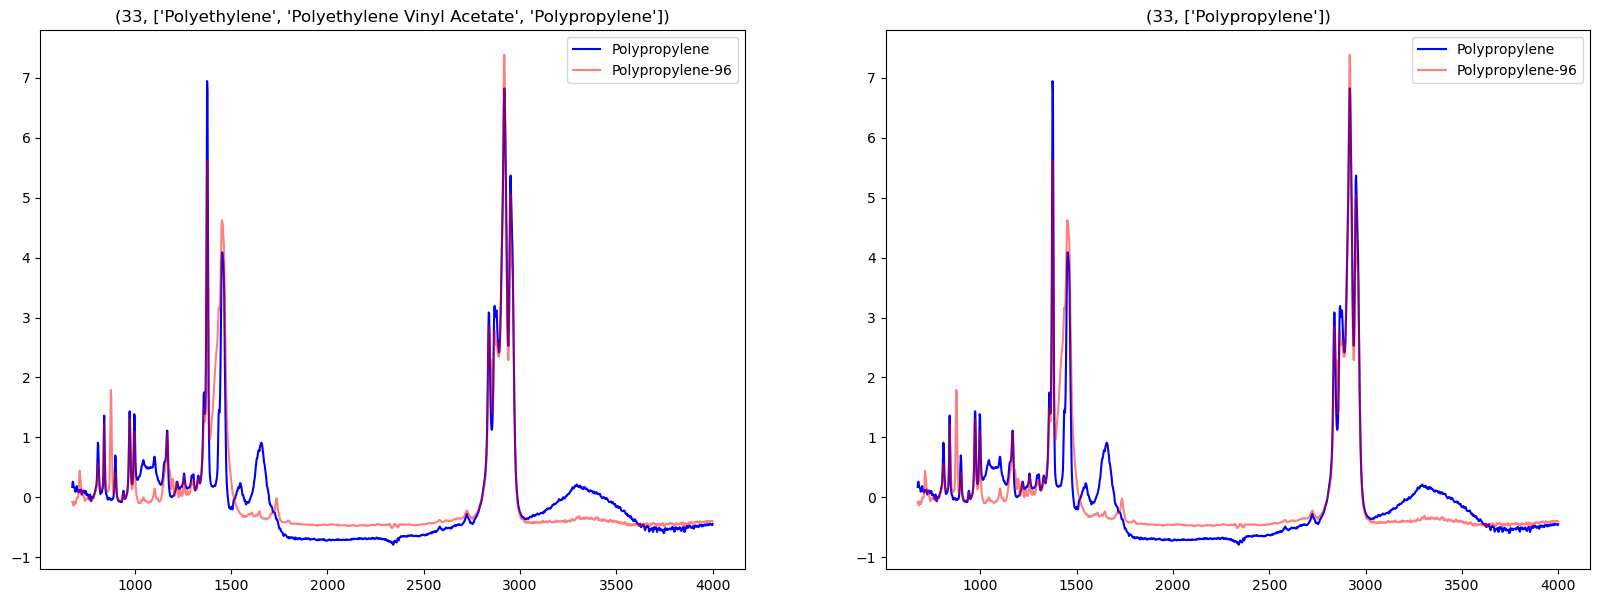

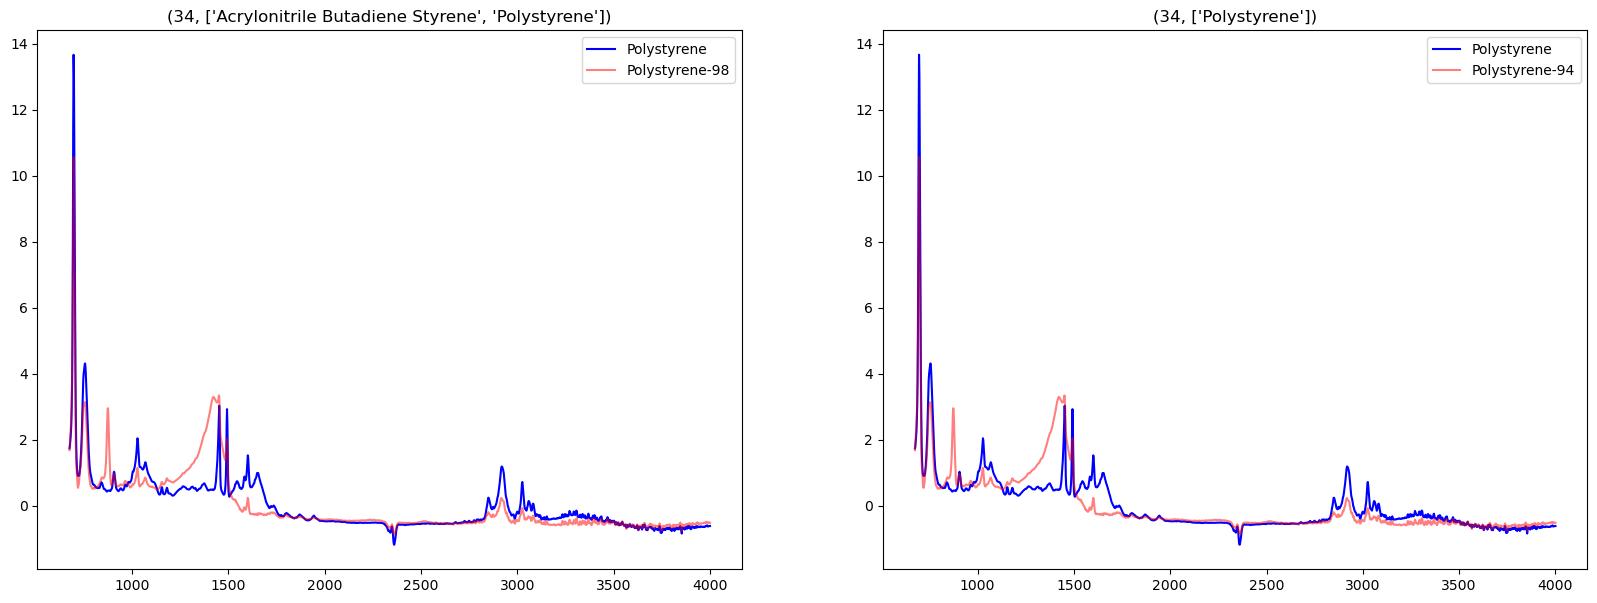

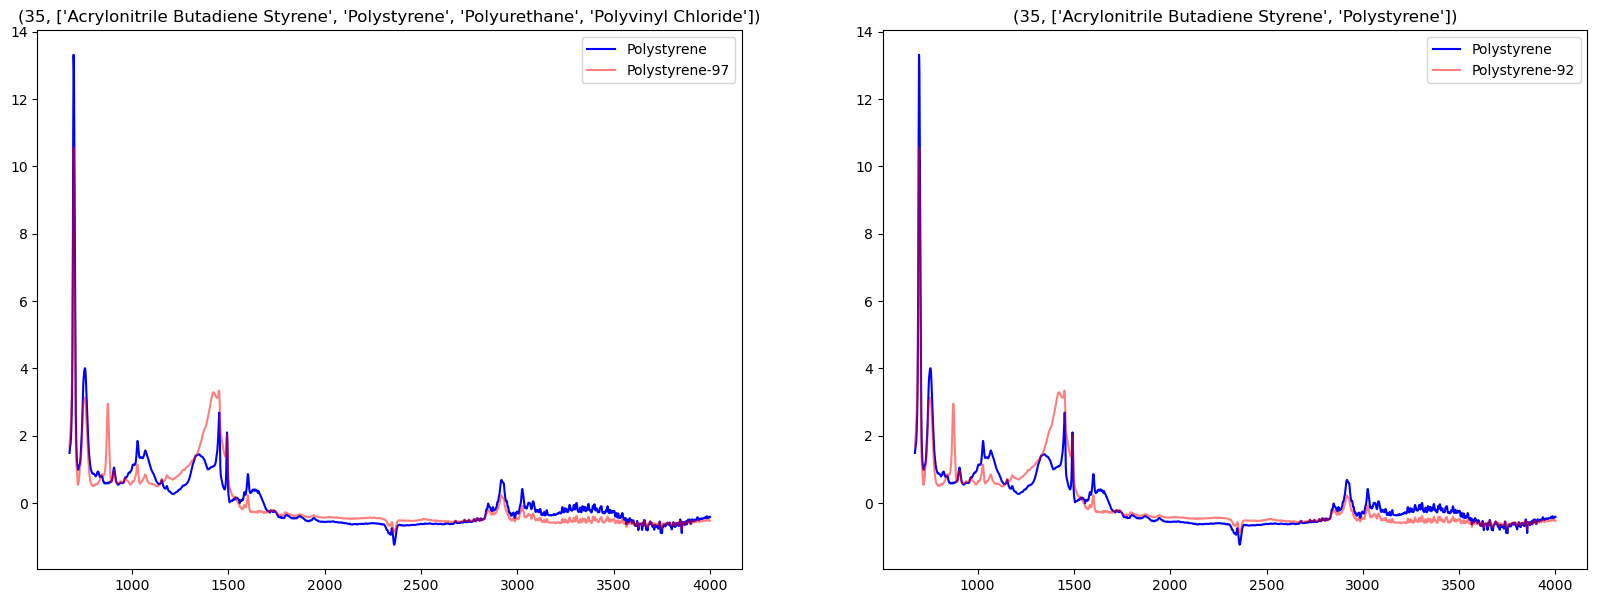

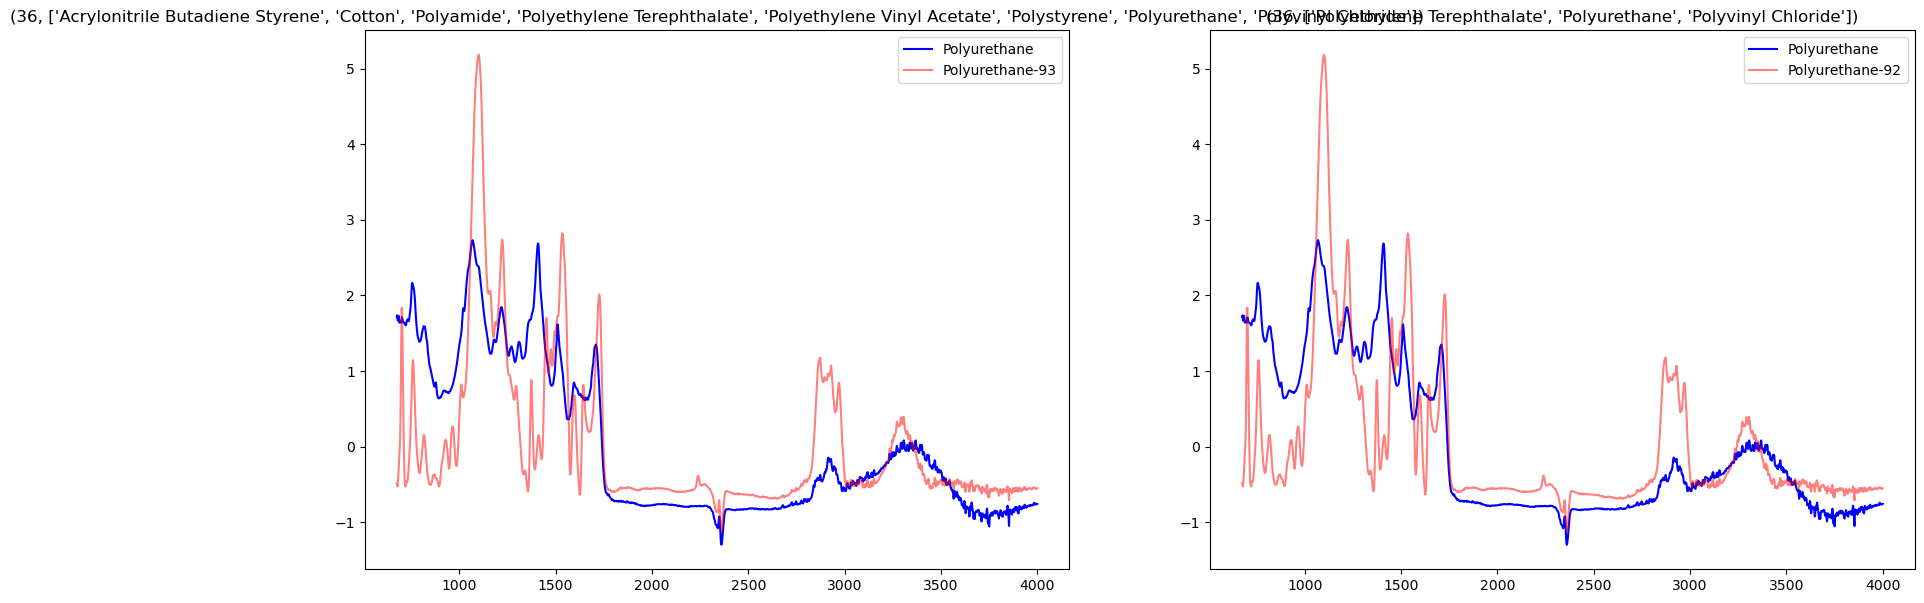

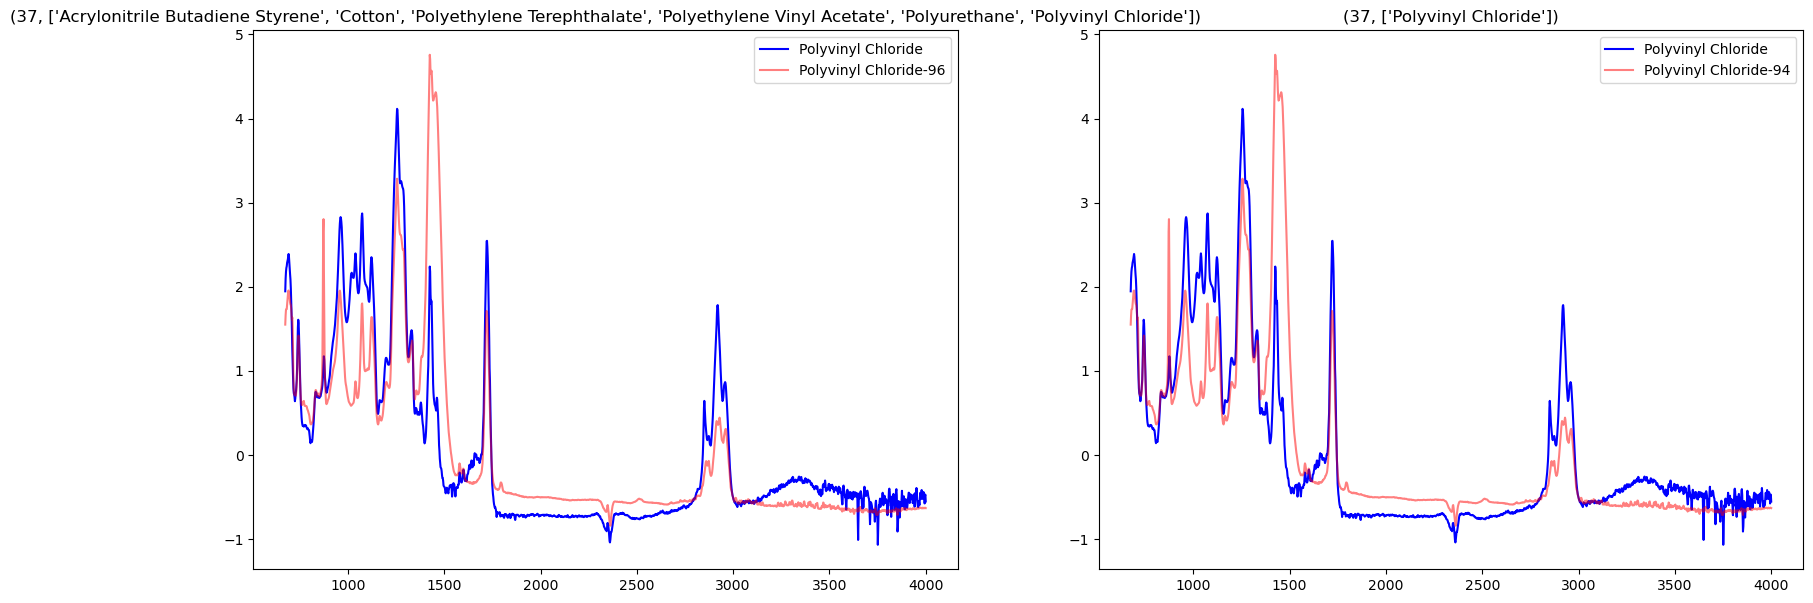

In [231]:
pred_hqi, score_hqi, score_hqi2 = np.argmax(val_smx, 1), np.max(val_smx, 1), np.max(val_smx2, 1)
pred_hqi_poly = np.array(label_table.iloc[pred_hqi, 1])
#pred_hqi = pred_hqi.to_numpy()

#label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})
prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(38)]
prediction_sets_label2 = [label_table.loc[prediction_sets2[i], 'polymer'].to_list() for i in range(38)]
#prediction_sets_label_cond = [label_table.loc[prediction_sets_cond[i], 'polymer'].to_list() for i in range(95)]

for i in range(38):#np.argsort(score_hqi)[::-1]:
    #if len(prediction_sets_label[i]) >2:
    #    continue
    fig, ax = plt.subplots(nrows=1, ncols=2)
    fig.set_figheight(7)
    fig.set_figwidth(20) 
    #print(prediction_sets_label[i])
    
    ax[0].set_title((i, prediction_sets_label[i]))
    ax[0].plot(wl_list, -X_test[~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])
    ax[0].plot(wl_list, -X_train[label_train==pred_hqi[i]][0,:], c='r', alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi[i]*100)))
    ax[0].legend()
    
    ax[1].set_title((i, prediction_sets_label2[i]))
    ax[1].plot(wl_list, -X_test[~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])
    ax[1].plot(wl_list, -X_train[label_train==pred_hqi[i]][0,:], c='r', alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi2[i]*100)))
    ax[1].legend()
    
    #print(prediction_sets_label_cond[i])
    
    #ax[1].set_title(prediction_sets_label_cond[i])
    #ax[1].plot(wl_list, X_test[~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])
    #ax[1].plot(wl_list, X_train[label_train==pred_hqi[i]][0,:], c='r', alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi[i]*100)))
    #ax[1].legend()

    fig.show()


In [230]:
val_labels.shape

(38,)

In [173]:
val_smx[9,:]

array([0.42394944, 0.18760546, 0.43059505, 0.11557794, 0.99871696,
       0.29586301, 0.88779821, 0.8465872 , 0.37017131, 0.24975442,
       0.34287581])

In [257]:
import matplotlib.colors as mcolors
import math

import matplotlib.pyplot as plt

import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
def plot_colortable(colors, *, ncols=4, sort_colors=True):

    cell_width = 212
    cell_height = 22
    swatch_width = 48
    margin = 12

    # Sort colors by hue, saturation, value and name.
    if sort_colors is True:
        names = sorted(
            colors, key=lambda c: tuple(mcolors.rgb_to_hsv(mcolors.to_rgb(c))))
    else:
        names = list(colors)

    n = len(names)
    nrows = math.ceil(n / ncols)

    width = cell_width * ncols + 2 * margin
    height = cell_height * nrows + 2 * margin
    dpi = 72

    fig, ax = plt.subplots(figsize=(width / dpi, height / dpi), dpi=dpi)
    fig.subplots_adjust(margin/width, margin/height,
                        (width-margin)/width, (height-margin)/height)
    ax.set_xlim(0, cell_width * ncols)
    ax.set_ylim(cell_height * (nrows-0.5), -cell_height/2.)
    ax.yaxis.set_visible(False)
    ax.xaxis.set_visible(False)
    ax.set_axis_off()

    for i, name in enumerate(names):
        row = i % nrows
        col = i // nrows
        y = row * cell_height

        swatch_start_x = cell_width * col
        text_pos_x = cell_width * col + swatch_width + 7

        ax.text(text_pos_x, y, name, fontsize=14,
                horizontalalignment='left',
                verticalalignment='center')

        ax.add_patch(
            Rectangle(xy=(swatch_start_x, y-9), width=swatch_width,
                      height=18, facecolor=colors[name], edgecolor='0.7')
        )

    return fig


In [293]:
names = sorted(
            mcolors.CSS4_COLORS, key=lambda c: tuple(mcolors.rgb_to_hsv(mcolors.to_rgb(c))))
colors = np.array(names[117:117+11])
np.random.shuffle(names)
names

['dimgrey',
 'navajowhite',
 'orangered',
 'darkslategrey',
 'salmon',
 'ivory',
 'teal',
 'cyan',
 'red',
 'azure',
 'burlywood',
 'mediumslateblue',
 'midnightblue',
 'beige',
 'darkviolet',
 'tan',
 'hotpink',
 'palevioletred',
 'darkcyan',
 'mediumseagreen',
 'tomato',
 'fuchsia',
 'white',
 'lightslategrey',
 'thistle',
 'darkkhaki',
 'lightsalmon',
 'dimgray',
 'linen',
 'orchid',
 'cornsilk',
 'darkturquoise',
 'darkblue',
 'lawngreen',
 'moccasin',
 'darkslateblue',
 'lightcoral',
 'mistyrose',
 'darkmagenta',
 'lightcyan',
 'darkolivegreen',
 'antiquewhite',
 'lavender',
 'lightsteelblue',
 'seagreen',
 'cornflowerblue',
 'grey',
 'lightgreen',
 'mediumpurple',
 'darkgrey',
 'lightblue',
 'chartreuse',
 'powderblue',
 'lightpink',
 'whitesmoke',
 'aquamarine',
 'palegreen',
 'firebrick',
 'royalblue',
 'magenta',
 'deepskyblue',
 'coral',
 'lime',
 'peru',
 'darkred',
 'saddlebrown',
 'indigo',
 'maroon',
 'gold',
 'rosybrown',
 'springgreen',
 'lemonchiffon',
 'darksalmon',
 

Polyethylene Vinyl Acetate
Polyethylene
Polyethylene Terephthalate
Polypropylene


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/1581791464.py:23: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


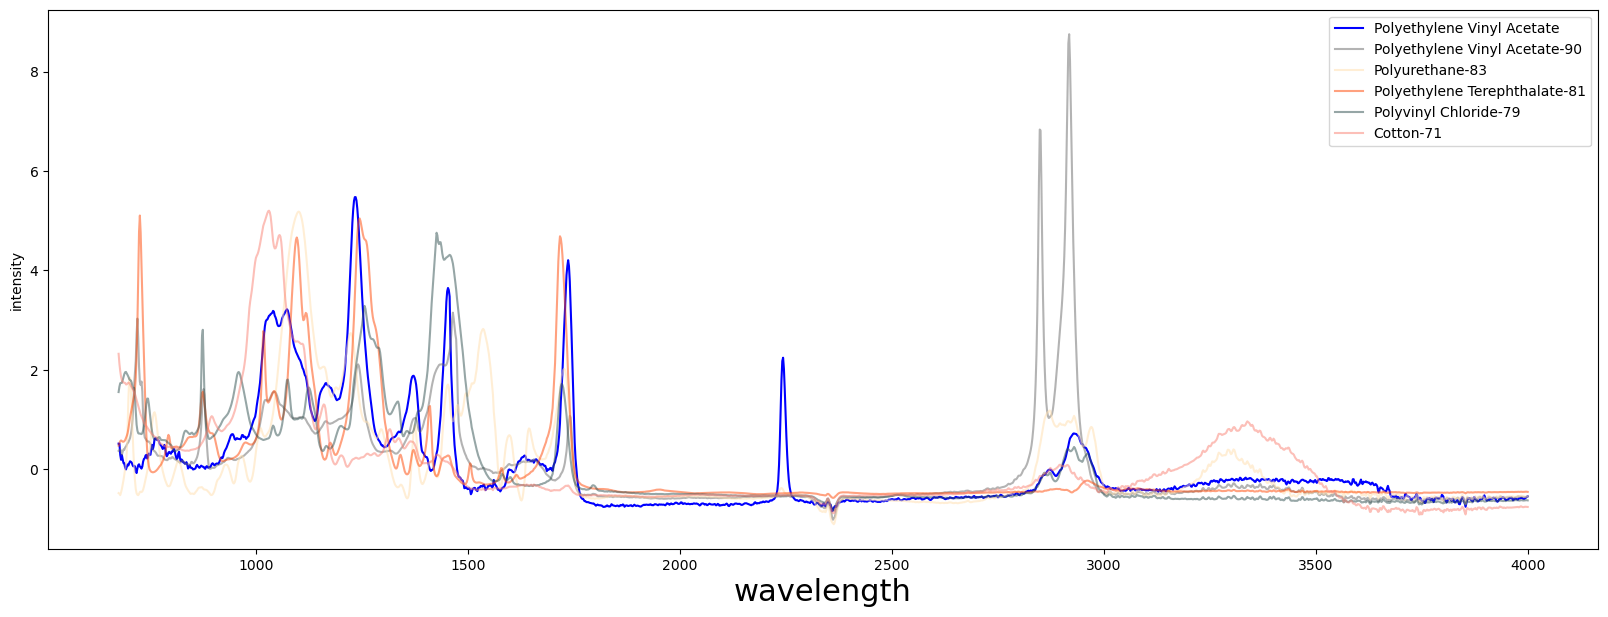

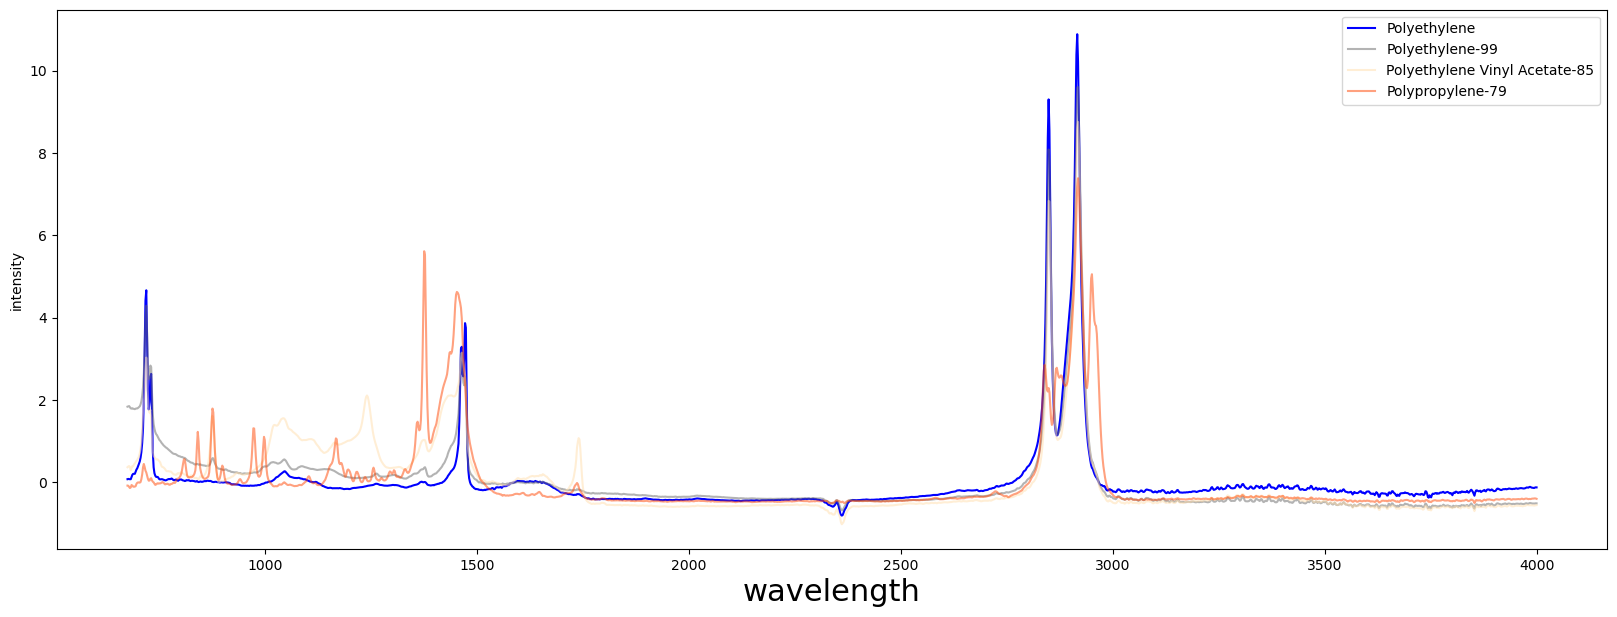

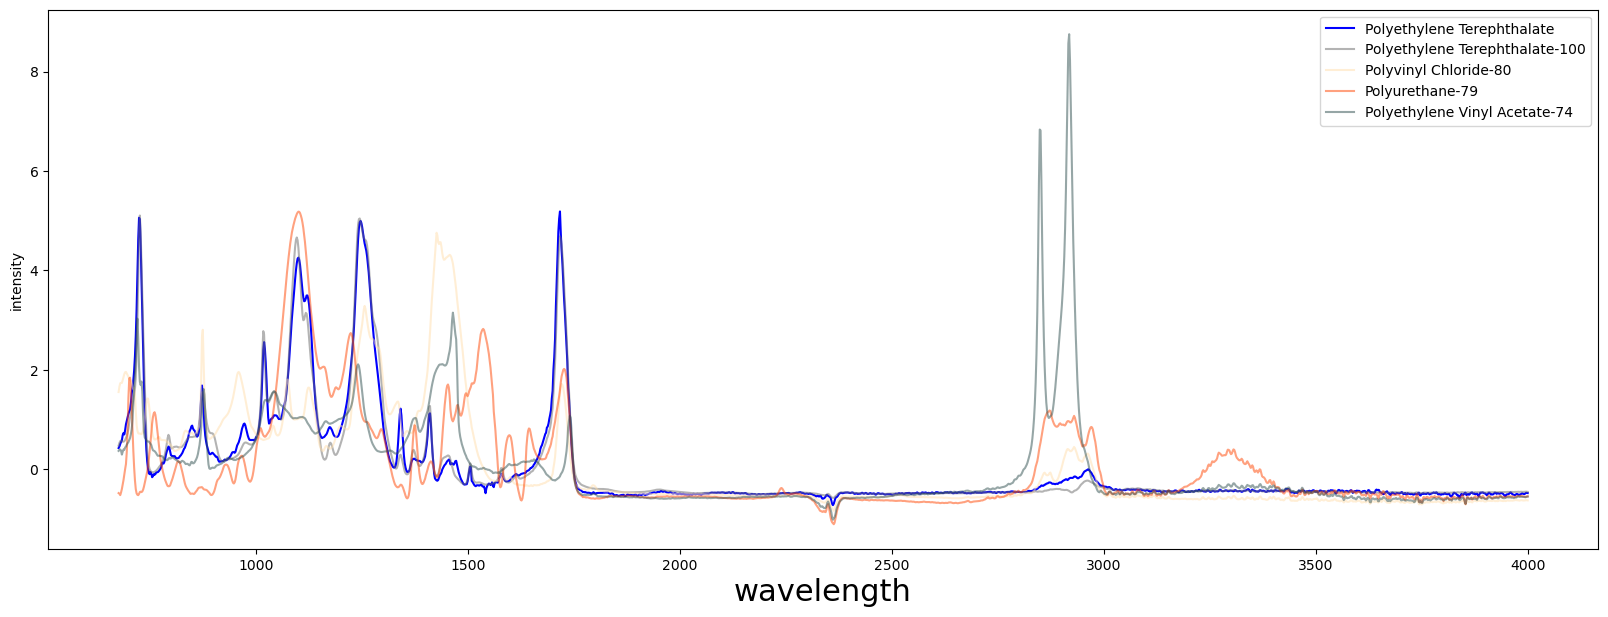

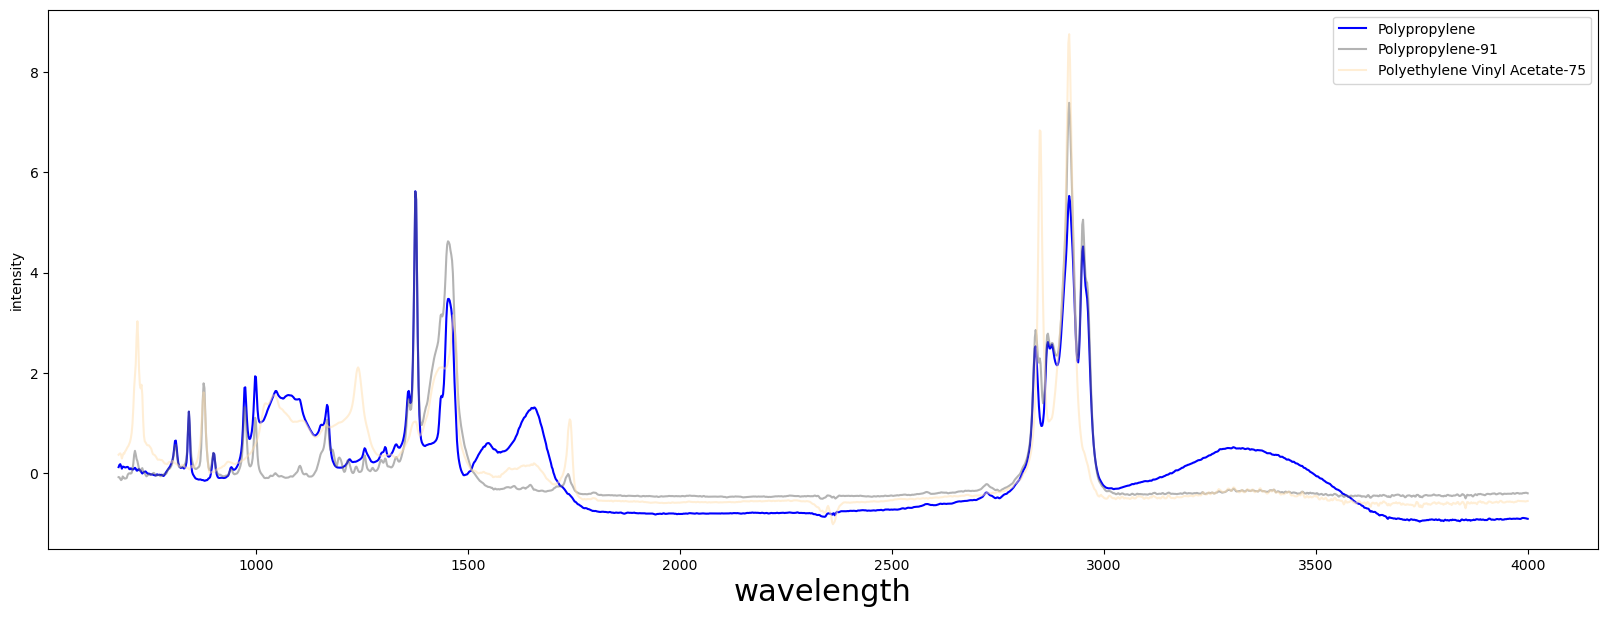

In [325]:
#fig, ax = plt.subplots(nrows=4, ncols=1)
#fig.set_figheight(30)
#fig.set_figwidth(20) 

for l, i in enumerate([3, 6,18,27]):
    fig, ax = plt.subplots(nrows=1, ncols=1)
    fig.set_figheight(7)
    fig.set_figwidth(20) 
    print(label_table.iloc[val_labels[i],1])
    #ax[l].set_title((i, prediction_sets_label[i]))
    ax.plot(wl_list, -X_test[~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])
    pred_set = np.where(prediction_sets[i])[0]
    ord_pred_set = np.argsort(val_smx[i,np.where(prediction_sets[i])[0]])[::-1]
    for k, j in enumerate(pred_set[ord_pred_set]):
        ax.plot(wl_list, 
                -X_train[label_train==j][0,:], 
                c=names[k], 
                alpha=.5, 
                label=str(label_table.iloc[j,1]) + '-' + str(round(val_smx[i, j]*100)))
    ax.set_xlabel('wavelength', fontsize=22)
    ax.set_ylabel('intensity')
    ax.legend()
    fig.show()

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/664940381.py:20: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


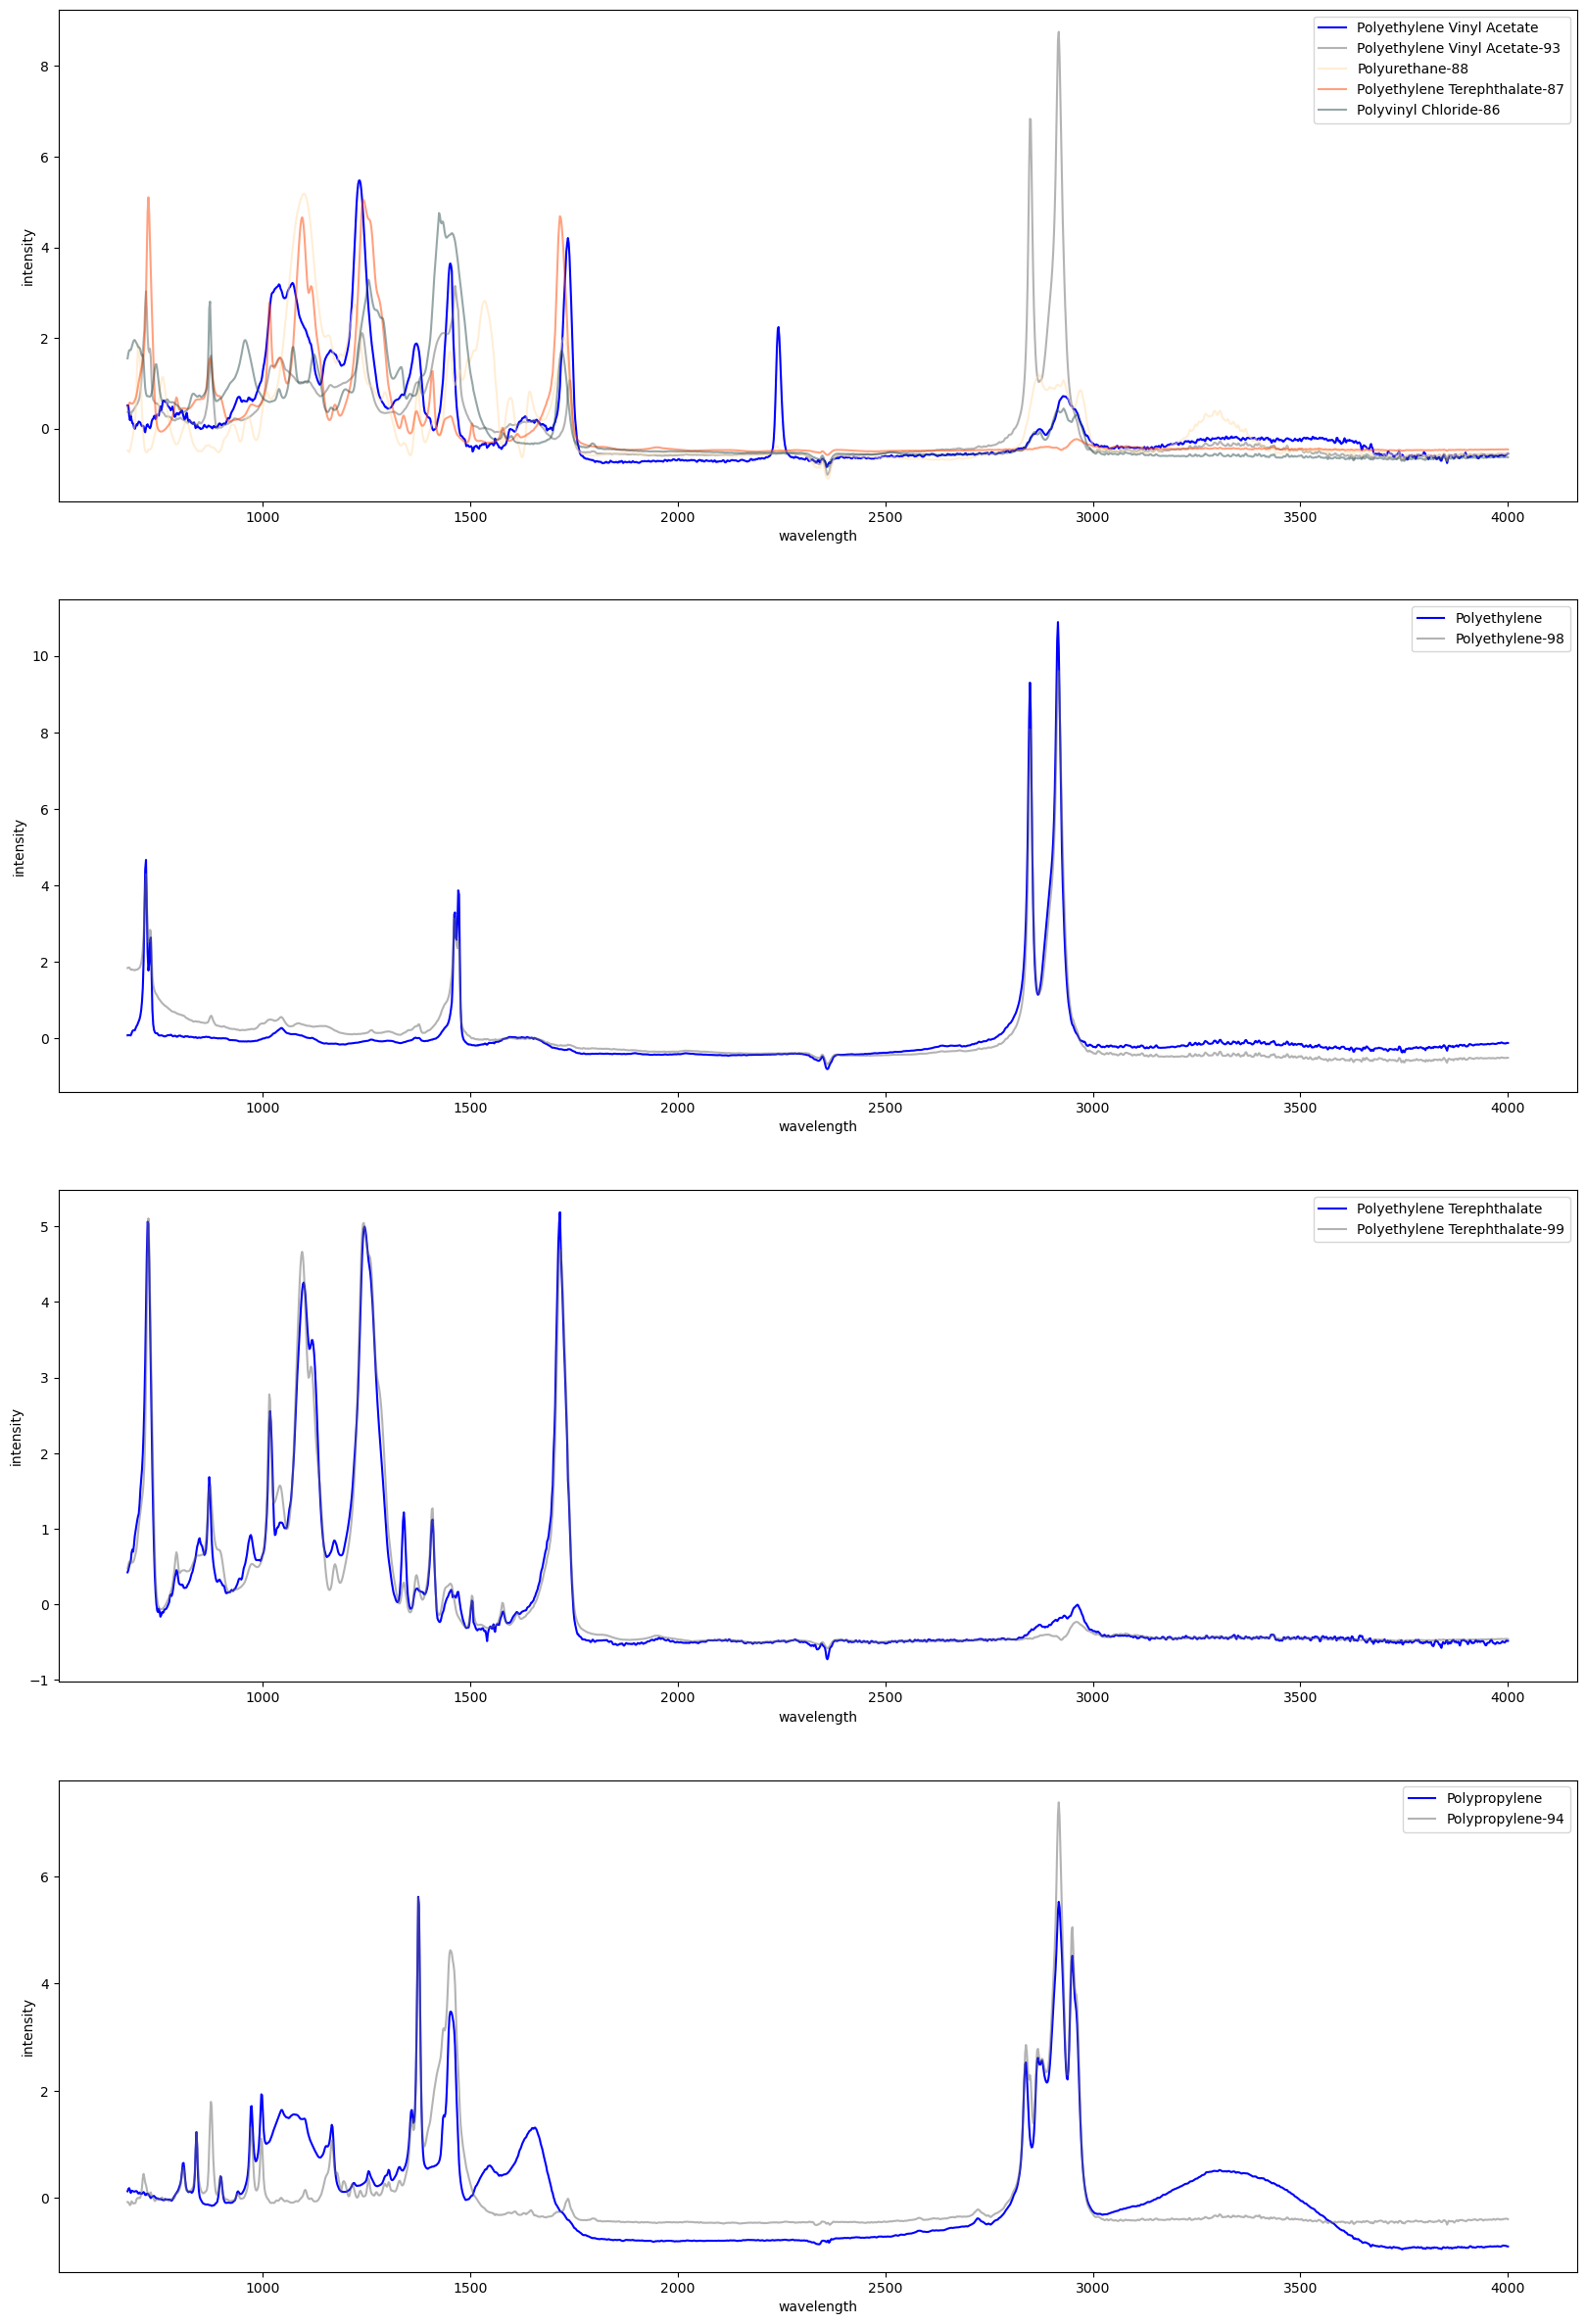

In [318]:
fig, ax = plt.subplots(nrows=4, ncols=1)
fig.set_figheight(30)
fig.set_figwidth(20) 

for l, i in enumerate([3, 6,18,27]):
    
    #ax[l].set_title((i, prediction_sets_label2[i]))
    ax[l].plot(wl_list, -X_test[~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])
    pred_set = np.where(prediction_sets2[i])[0]
    ord_pred_set = np.argsort(val_smx[i,np.where(prediction_sets2[i])[0]])[::-1]
    for k, j in enumerate(pred_set[ord_pred_set]):
        ax[l].plot(wl_list, 
                -X_train[label_train==j][0,:], 
                c=names[k], 
                alpha=.5, 
                label=str(label_table.iloc[j,1]) + '-' + str(round(val_smx2[i, j]*100)))
    ax[l].legend()
    ax[l].set_xlabel('wavelength')
    ax[l].set_ylabel('intensity')
    fig.show()

In [ ]:
9,18,27

In [146]:
pred_hqi, score_hqi = np.argmax(val_smx, 1), np.max(val_smx, 1)
pred_hqi_poly = np.array(label_table.iloc[pred_hqi, 1])
#pred_hqi = pred_hqi.to_numpy()

#label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})
prediction_sets_label = [label_table.loc[prediction_sets_cond[i], 'polymer'].to_list() for i in range(95)]

for i in np.argsort(score_hqi)[::-1]:
    #if len(prediction_sets_label[i]) >2:
    #    continue
    print(prediction_sets_label[i])

    plt.plot(wl_list, -X_test[~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])

    #plt.plot(wl_list, X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list, X_train[label_train==pred_hqi[i]][0,:], c='r', alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi[i]*100)))

    plt.legend()

    plt.show()


NameError: name 'prediction_sets_cond' is not defined

In [27]:
val_smx

array([[0.62394942, 0.99061037, 0.39771564, ..., 0.49161015, 0.71422647,
        0.81194247],
       [0.7814738 , 0.90601675, 0.58352437, ..., 0.66457079, 0.88781425,
        0.91624525],
       [0.72887095, 0.97165428, 0.48259987, ..., 0.5459953 , 0.83398879,
        0.9091773 ],
       ...,
       [0.72369393, 0.75358919, 0.7385592 , ..., 0.71001241, 0.95003854,
        0.82444654],
       [0.76573841, 0.78021903, 0.58043152, ..., 0.65343041, 0.91285962,
        0.88439439],
       [0.82040787, 0.76193238, 0.59268472, ..., 0.71177801, 0.82718767,
        0.96943678]])

In [28]:
label_table_ex = pd.concat([label_table, pd.DataFrame(val_smx[80, :])],1)
label_table_ex.columns = ['label', 'polymer', 'hqi']
label_table_ex.query('hqi > 1-@qhat').sort_values(['polymer'])

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/1867575342.py:1: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  label_table_ex = pd.concat([label_table, pd.DataFrame(val_smx[80, :])],1)


,label,polymer,hqi


In [29]:
pd.DataFrame(val_smx[80, :])

,0
0,0.773586
1,0.849309
2,0.635495
3,0.505327
4,0.773530
5,0.777384
6,0.757791
7,0.743380
8,0.663927
9,0.890855


In [31]:
pred_hqi, score_hqi = np.argmax(val_smx, 1), np.max(val_smx, 1)
pred_hqi_poly = np.array(label_table.iloc[pred_hqi, 1])
#pred_hqi = pred_hqi.to_numpy()

#label_table = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_train).to_numpy())})
prediction_sets_label = [label_table.loc[prediction_sets[i], 'polymer'].to_list() for i in range(95)]

for i in np.argsort(score_hqi)[::-1]:
    #if len(prediction_sets_label[i]) >2:
    #    continue
    print(prediction_sets_label[i])

    plt.plot(wl_list, X_test[(smx < 0).sum(1) == 0,:][~idx][i,:], c='b', label=label_table.iloc[val_labels[i],1])

    #plt.plot(wl_list, X_train[y_train==y_test.to_numpy()[~idx][i]].iloc[0,].to_numpy(), c='g', alpha=.5, label='reference')

    plt.plot(wl_list, X_train[label_train==pred_hqi[i]][0,:], c='r', alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi[i]*100)))

    plt.legend()

    plt.show()


['Polyethylene']


IndexError: boolean index did not match indexed array along dimension 0; dimension is 185 but corresponding boolean dimension is 189

In [32]:
smx = clf.predict_proba(X_test)
smx.shape

(189, 11)

In [33]:
smx = clf.predict_proba(X_test)

alpha = 0.1
cal_smx, val_smx, cal_labels, val_labels = split_cal_test(smx, label_test, cal_prop=0.5)
n = cal_smx.shape[0]

(prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
prediction_sets.sum(1).mean(), empirical_coverage, qhat

ValueError: too many values to unpack (expected 4)

In [34]:
alphas = np.concatenate([np.linspace(0.01,0.05, 5),np.linspace(0.1,0.20, 3)])
alphas

array([0.01, 0.02, 0.03, 0.04, 0.05, 0.1 , 0.15, 0.2 ])

In [35]:
n

94

In [101]:
#smx = smx_hqi(X_train, X_test, label_train)

D = pairwise_distances(X_train, X_test)
df_D = pd.DataFrame(D)
df_D['polymer_ref'] = label_train
smx = (df_D.melt(id_vars=['polymer_ref']).
             groupby(['variable','polymer_ref']).
             min().
             reset_index().
             pivot(index='variable', columns='polymer_ref', values='value').
             to_numpy())
smx_1 = (smx / smx.min(1)[:,None])
smx_2 = (smx / np.sort(smx, 1)[:,1][:,None])
smx_1[smx_1 == 1] = smx_2[smx_1 == 1]
smx = np.exp(-smx_1/10)
smx = smx_hqi(X_train, X_test, label_train)

#id_correct = (smx < 0).sum(1) == 0

alpha = 0.05

res_dict_hqi = defaultdict(list) 
cov_by_label_hqi = defaultdict(list)
cov_by_set_size_hqi = defaultdict(list)
set_size_by_label_hqi = defaultdict(list)
qhat_dict = defaultdict(list)
qhat
for alpha in alphas:
    cov = np.zeros(500)
    set_size = np.zeros(500)
    qhat_list = np.zeros(500)
    zero_sets = np.zeros(500)
    one_sets = np.zeros(500)
    
    for i in range(500):
        
        cal_smx, val_smx, cal_labels, val_labels, _ = split_cal_test(smx, label_test, cal_prop=0.8)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        zero_sets[i] = (prediction_sets.sum(1) == 0).mean()
        one_sets[i] = (prediction_sets.sum(1) == 1).mean()
        qhat_list[i] = qhat
        
        cov_by_label_hqi[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('label').mean()* 100
    )
        cov_by_set_size_hqi[alpha].append(
        pd.DataFrame({'set_size':prediction_sets.sum(1), 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('set_size').mean()* 100
    )
        set_size_by_label_hqi[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_hqi['alpha'].append(alpha)    
    res_dict_hqi['cov_mean'].append(cov.mean())
    res_dict_hqi['set_size_mean'].append(set_size.mean())
    
    res_dict_hqi['cov_sd'].append(cov.std())
    res_dict_hqi['set_size_sd'].append(set_size.std())
    qhat_dict['set_size_sd'].append(qhat_list)
    res_dict_hqi['zero_sets'].append(zero_sets.mean())
    res_dict_hqi['one_sets'].append(one_sets.mean())
    
res_df_hqi = pd.DataFrame(res_dict_hqi)

In [77]:
#smx = smx_hqi(X_train, X_test, label_train)

D = pairwise_distances(X_train, X_test)
df_D = pd.DataFrame(D)
df_D['polymer_ref'] = label_train
smx = (df_D.melt(id_vars=['polymer_ref']).
             groupby(['variable','polymer_ref']).
             min().
             reset_index().
             pivot(index='variable', columns='polymer_ref', values='value').
             to_numpy())
smx_1 = (smx / smx.min(1)[:,None])
smx_2 = (smx / np.sort(smx, 1)[:,1][:,None])
smx_1[smx_1 == 1] = smx_2[smx_1 == 1]
smx = np.exp(-smx_1/10)
#smx = smx_nn(X_train, X_test, label_train)

#id_correct = (smx < 0).sum(1) == 0

alpha = 0.05

res_dict_hqi = defaultdict(list) 
cov_by_label_hqi2 = defaultdict(list)
cov_by_set_size_hqi2 = defaultdict(list)
set_size_by_label_hqi2 = defaultdict(list)
qhat_dict = defaultdict(list)
zero_sets_dict = defaultdict(list)

for alpha in alphas:
    cov = np.zeros(500)
    set_size = np.zeros(500)
    qhat_list = np.zeros(500)
    zero_sets = np.zeros(500)
    one_sets = np.zeros(500)

    for i in range(500):
        
        cal_smx, val_smx, cal_labels, val_labels, _ = split_cal_test(smx, label_test, cal_prop=0.8)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        zero_sets[i] = (prediction_sets.sum(1) == 0).mean()
        one_sets[i] = (prediction_sets.sum(1) == 1).mean()
        qhat_list[i] = qhat
        
        cov_by_label_hqi2[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('label').mean()* 100
    )
        
        cov_by_set_size_hqi2[alpha].append(
        pd.DataFrame({'set_size':prediction_sets.sum(1), 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('set_size').mean()* 100
    )   
        set_size_by_label_hqi2[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_hqi['alpha'].append(alpha)    
    res_dict_hqi['cov_mean'].append(cov.mean())
    res_dict_hqi['set_size_mean'].append(set_size.mean())
    
    res_dict_hqi['cov_sd'].append(cov.std())
    res_dict_hqi['set_size_sd'].append(set_size.std())
    qhat_dict['set_size_sd'].append(qhat_list)
    res_dict_hqi['zero_sets'].append(zero_sets.mean())
    res_dict_hqi['one_sets'].append(one_sets.mean())
    
res_df_hqi2 = pd.DataFrame(res_dict_hqi)

In [544]:
smx = clf.predict_proba(X_test)

alpha = 0.1
res_dict_log = defaultdict(list) 
cov_by_label_log = defaultdict(list)
set_size_by_label_log = defaultdict(list)
for alpha in alphas:
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)
    zero_sets = np.zeros(500)
    one_sets = np.zeros(500)

    for i in range(500):
        
        cal_smx, val_smx, cal_labels, val_labels, _ = split_cal_test(smx, label_test, cal_prop=0.8)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), _ = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        zero_sets[i] = (prediction_sets.sum(1) == 0).mean()
        one_sets[i] = (prediction_sets.sum(1) == 1).mean()
        
        cov_by_label_log[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('label').mean()* 100
    )
        set_size_by_label_log[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_log['alpha'].append(alpha)    
    res_dict_log['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict_log['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict_log['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict_log['set_size_sd'].append(set_size.std())
    res_dict_log['zero_sets'].append(zero_sets.mean())
    res_dict_log['one_sets'].append(one_sets.mean())
    #res_dict['acc_sd'].append(acc.std())

res_df_log = pd.DataFrame(res_dict_log)


In [38]:
set_size_by_label_list = []
for df in [set_size_by_label_hqi[0.05], set_size_by_label_hqi2[0.05], set_size_by_label_log[0.05]]:
    set_size_by_label_table = (pd.concat(df).
     groupby('label').
     mean().
     merge(label_table, left_index=True, right_on='label'))#.
     #merge(pd.concat(set_size_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
    del set_size_by_label_table['label']
    set_size_by_label_table.columns = ['set size','polymer']
    set_size_by_label_table = np.round(set_size_by_label_table.set_index('polymer').sort_values('set size'), 2)
    set_size_by_label_list.append(set_size_by_label_table)

NameError: name 'set_size_by_label_log' is not defined

In [145]:
pd.DataFrame({'alpha':cov_by_set_size_hqi.keys(), 'qhat':1-np.array(qhat_dict['set_size_sd']).mean(1)})

,alpha,qhat
0,0.01,0.432029
1,0.02,0.531803
2,0.03,0.618428
3,0.04,0.690419
4,0.05,0.706856
5,0.10,0.825435
6,0.15,0.866377
7,0.20,0.891141


In [127]:
for alpha in cov_by_set_size_hqi.keys():
    cov_by_set_size_list = []
    for df in [cov_by_set_size_hqi[alpha], cov_by_set_size_hqi2[alpha]]:
        cov_by_label_table = (pd.concat(df).
         groupby('set_size').
         mean()).reset_index()#.
         #merge(label_table, left_index=True, right_on='set_size'))#.
         #merge(pd.concat(set_size_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
        #del cov_by_label_table['set_size']
        #cov_by_label_table.columns = ['cov','polymer']
        cov_by_label_table = np.round(cov_by_label_table.set_index('set_size'), 2)#.sort_values('coverage')
        cov_by_set_size_list.append(cov_by_label_table)
    print(1-alpha,(cov_by_set_size_list[0].
 merge(cov_by_set_size_list[1], left_index=True, right_index=True).
 query('coverage_x>0 and coverage_y>0')).min())

0.99 coverage_x    96.36
coverage_y    76.63
dtype: float64
0.98 coverage_x    95.23
coverage_y    78.33
dtype: float64
0.97 coverage_x    96.40
coverage_y    70.85
dtype: float64
0.96 coverage_x    25.58
coverage_y    79.66
dtype: float64
0.95 coverage_x    84.44
coverage_y    78.01
dtype: float64
0.9 coverage_x    82.76
coverage_y    34.89
dtype: float64
0.85 coverage_x    86.13
coverage_y    65.06
dtype: float64
0.8 coverage_x    92.89
coverage_y    91.11
dtype: float64


In [128]:
set_size_by_label_list = []
for df in [set_size_by_label_hqi[0.05], set_size_by_label_hqi2[0.05]]:
    set_size_by_label_table = (pd.concat(df).
     groupby('label').
     mean().
     merge(label_table, left_index=True, right_on='label'))#.
     #merge(pd.concat(set_size_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
    del set_size_by_label_table['label']
    set_size_by_label_table.columns = ['set size','polymer']
    set_size_by_label_table = np.round(set_size_by_label_table.set_index('polymer').sort_values('set size'), 2)
    set_size_by_label_list.append(set_size_by_label_table)

In [129]:
(set_size_by_label_list[0].
 merge(set_size_by_label_list[1], on='polymer').
 merge(set_size_by_label_list[2], on='polymer'))

IndexError: list index out of range

In [130]:
(set_size_by_label_list[0].
 merge(set_size_by_label_list[1], on='polymer'))

,set size_x,set size_y
polymer,,
Acrylonitrile Butadiene Styrene,2.00,1.00
Polyamide,2.96,1.62
Polystyrene,3.04,1.60
Polyethylene,3.45,1.88
Cotton,3.90,1.21
Polypropylene,3.98,2.60
Polyethylene Terephthalate,4.01,1.00
Polycarbonate,4.71,1.00
Polyethylene Vinyl Acetate,4.89,5.94


In [132]:
cov_by_label_list = []
for df in [cov_by_label_hqi[0.05], cov_by_label_hqi2[0.05]]:
    cov_by_label_table = (pd.concat(df).
     groupby('label').
     mean().
     merge(label_table, left_index=True, right_on='label'))#.
     #merge(pd.concat(set_size_by_label[0.06076923076923077]).groupby('label').count(), left_on='id', right_on='label'))
    del cov_by_label_table['label']
    cov_by_label_table.columns = ['cov','polymer']
    cov_by_label_table = np.round(cov_by_label_table.set_index('polymer').sort_values('cov'), 2)
    cov_by_label_list.append(cov_by_label_table)
    

In [133]:
(cov_by_label_list[0].
 merge(cov_by_label_list[1], on='polymer'))

,cov_x,cov_y
polymer,,
Polypropylene,90.20,92.84
Polyethylene,97.84,94.86
Polyethylene Vinyl Acetate,99.39,100.00
Acrylonitrile Butadiene Styrene,100.00,100.00
Cotton,100.00,100.00
Polyamide,100.00,100.00
Polycarbonate,100.00,100.00
Polyethylene Terephthalate,100.00,100.00
Polystyrene,100.00,99.72


(0.795, 0.995)

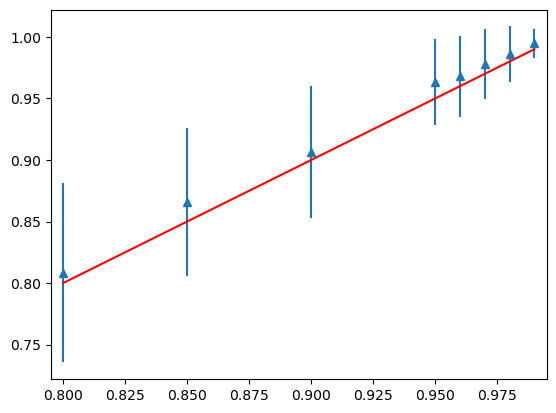

In [499]:
plt.errorbar(1-res_df_log['alpha'], res_df_log['cov_mean'], res_df_log['cov_sd'], linestyle='None', marker='^')
plt.plot(1-alphas, 1-alphas, c='r')
plt.xlim(0.795,.995)

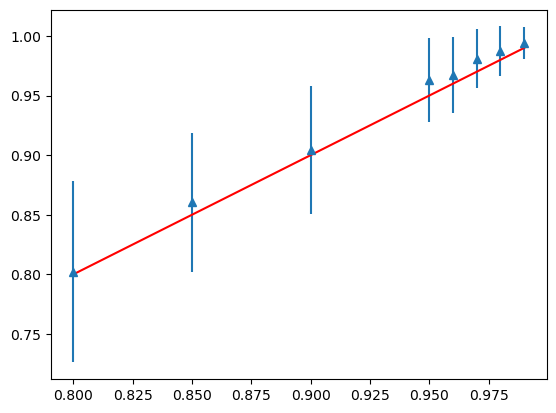

In [500]:
plt.errorbar(1-res_df_hqi['alpha'], res_df_hqi['cov_mean'], res_df_hqi['cov_sd'], linestyle='None', marker='^')
plt.plot(1-alphas, 1-alphas, c='r')

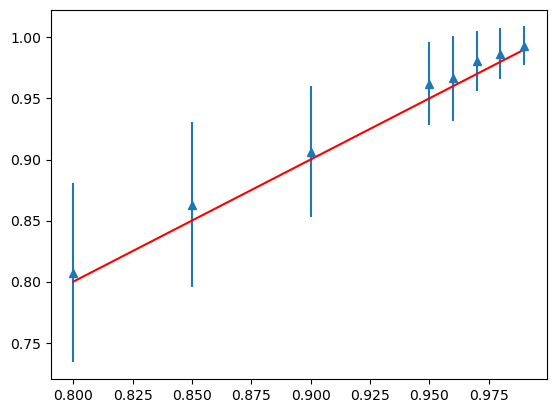

In [501]:
plt.errorbar(1-res_df_hqi2['alpha'], res_df_hqi2['cov_mean'], res_df_hqi2['cov_sd'], linestyle='None', marker='^')
plt.plot(1-alphas, 1-alphas, c='r')

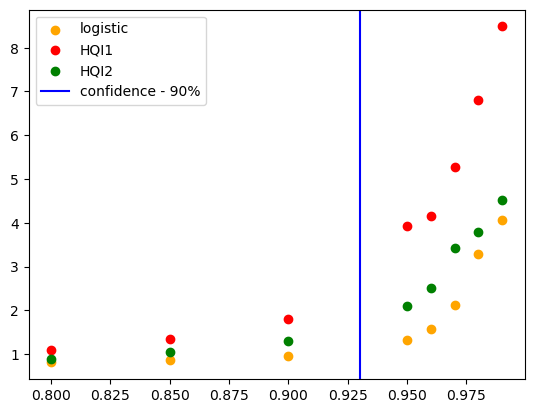

In [502]:
plt.scatter(1-res_df_log['alpha'], res_df_log['set_size_mean'], c='orange', label='logistic')
plt.scatter(1-res_df_hqi['alpha'], res_df_hqi['set_size_mean'], c='red', label='HQI1')
plt.scatter(1-res_df_hqi2['alpha'], res_df_hqi2['set_size_mean'], c='g', label='HQI2')
plt.axvline(x = 0.93, color = 'b', label = 'confidence - 90%')
plt.legend()

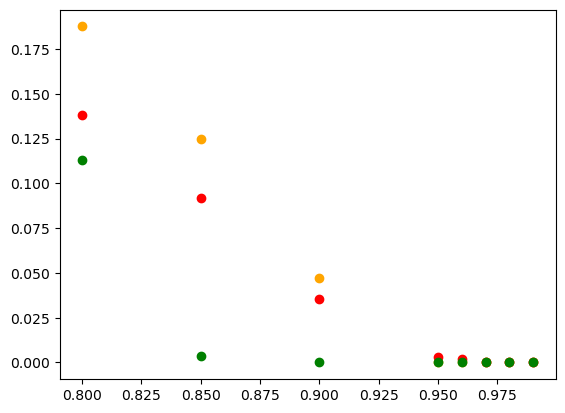

In [503]:
plt.scatter(1-res_df_log['alpha'], res_df_log['zero_sets'], c='orange', label='logistic')
plt.scatter(1-res_df_hqi['alpha'], res_df_hqi['zero_sets'], c='red', label='HQI1')
plt.scatter(1-res_df_hqi2['alpha'], res_df_hqi2['zero_sets'], c='g', label='HQI2')

In [65]:
res_df_hqi

,alpha,cov_mean,set_size_mean,cov_sd,set_size_sd,zero_sets,one_sets
0,0.01,0.994684,8.507947,0.012488,0.788009,0.000000,0.000000
1,0.02,0.986737,6.792684,0.020620,1.140858,0.000000,0.000632
2,0.03,0.980895,5.312842,0.024389,0.595481,0.000105,0.002158
3,0.04,0.966789,4.176789,0.031638,0.374945,0.001789,0.006579
4,0.05,0.959895,3.889947,0.037155,0.436757,0.003947,0.013316
5,0.10,0.908211,1.840000,0.051634,0.319454,0.033789,0.405895
6,0.15,0.861421,1.359684,0.061599,0.141504,0.089895,0.545158
7,0.20,0.809105,1.106895,0.066060,0.123528,0.131368,0.644947


In [611]:
df_marg_cov = (res_df_hqi.loc[:, ['alpha', 'cov_mean', 'cov_sd']].
 merge(res_df_hqi2.loc[:, ['alpha', 'cov_mean', 'cov_sd']], on='alpha').
 merge(res_df_log.loc[:, ['alpha', 'cov_mean', 'cov_sd']], on='alpha'))
df_marg_cov

,alpha,cov_mean_x,cov_sd_x,cov_mean_y,cov_sd_y,cov_mean,cov_sd
0,0.01,0.993632,0.013811,0.993474,0.014474,0.993368,0.014232
1,0.02,0.986579,0.021345,0.987421,0.019649,0.986579,0.021603
2,0.03,0.979789,0.025544,0.980368,0.025426,0.980421,0.025439
3,0.04,0.967421,0.032714,0.968211,0.032324,0.967211,0.032375
4,0.05,0.961526,0.034758,0.960211,0.034731,0.961895,0.034264
5,0.10,0.915158,0.051203,0.907263,0.050107,0.908842,0.052557
6,0.15,0.866053,0.061614,0.866842,0.063445,0.860526,0.059813
7,0.20,0.807105,0.070244,0.808474,0.071860,0.808684,0.070481


In [46]:
df_marg_cov = (res_df_hqi.loc[:, ['alpha', 'cov_mean', 'cov_sd']].
 merge(res_df_hqi2.loc[:, ['alpha', 'cov_mean', 'cov_sd']], on='alpha'))
df_marg_cov['alpha'] = 1-df_marg_cov['alpha']
df_marg_cov

,alpha,cov_mean_x,cov_sd_x,cov_mean_y,cov_sd_y
0,0.99,0.994684,0.012488,0.993105,0.014731
1,0.98,0.986737,0.020620,0.986316,0.021340
2,0.97,0.980895,0.024389,0.978842,0.024199
3,0.96,0.966789,0.031638,0.966684,0.032308
4,0.95,0.959895,0.037155,0.961263,0.036056
5,0.90,0.908211,0.051634,0.907211,0.053216
6,0.85,0.861421,0.061599,0.857684,0.064811
7,0.80,0.809105,0.066060,0.812895,0.070779


In [47]:
print(df_marg_cov.to_latex(index=False,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{rrrrr}
\toprule
 alpha &  cov\_mean\_x &  cov\_sd\_x &  cov\_mean\_y &  cov\_sd\_y \\
\midrule
  0.99 &        0.99 &      0.01 &        0.99 &      0.01 \\
  0.98 &        0.99 &      0.02 &        0.99 &      0.02 \\
  0.97 &        0.98 &      0.02 &        0.98 &      0.02 \\
  0.96 &        0.97 &      0.03 &        0.97 &      0.03 \\
  0.95 &        0.96 &      0.04 &        0.96 &      0.04 \\
  0.90 &        0.91 &      0.05 &        0.91 &      0.05 \\
  0.85 &        0.86 &      0.06 &        0.86 &      0.06 \\
  0.80 &        0.81 &      0.07 &        0.81 &      0.07 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/2330629231.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_marg_cov.to_latex(index=False,


In [623]:
df_set_size = (res_df_hqi.loc[:, ['alpha', 'set_size_mean', 'set_size_sd']].
 merge(res_df_hqi2.loc[:, ['alpha', 'set_size_mean', 'set_size_sd']], on='alpha').
 merge(res_df_log.loc[:, ['alpha', 'set_size_mean', 'set_size_sd']], on='alpha'))
df_set_size

,alpha,set_size_mean_x,set_size_sd_x,set_size_mean_y,set_size_sd_y,set_size_mean,set_size_sd
0,0.01,8.427211,0.794822,4.545526,0.685125,4.060105,0.594229
1,0.02,6.802579,1.170837,3.745632,0.560267,3.289105,0.892093
2,0.03,5.246579,0.614651,3.388579,0.616749,2.146053,0.339708
3,0.04,4.206000,0.388753,2.480000,0.533804,1.573316,0.309866
4,0.05,3.902053,0.413810,2.094158,0.360021,1.311842,0.233905
5,0.10,1.886895,0.336720,1.320526,0.138231,0.954947,0.044419
6,0.15,1.355947,0.135298,1.058526,0.058311,0.870158,0.062991
7,0.20,1.110684,0.130987,0.889421,0.077751,0.813947,0.070579


In [52]:
df_set_size = (res_df_hqi.loc[:, ['alpha', 'set_size_mean', 'set_size_sd']].
 merge(res_df_hqi2.loc[:, ['alpha', 'set_size_mean', 'set_size_sd']], on='alpha'))
df_set_size['alpha'] = 1-df_set_size['alpha']
df_set_size

,alpha,set_size_mean_x,set_size_sd_x,set_size_mean_y,set_size_sd_y
0,0.99,8.507947,0.788009,4.525632,0.695811
1,0.98,6.792684,1.140858,3.768105,0.584206
2,0.97,5.312842,0.595481,3.422579,0.627952
3,0.96,4.176789,0.374945,2.464421,0.526039
4,0.95,3.889947,0.436757,2.131526,0.370358
5,0.90,1.840000,0.319454,1.321000,0.140711
6,0.85,1.359684,0.141504,1.051105,0.058600
7,0.80,1.106895,0.123528,0.894105,0.074094


In [53]:
print(df_set_size.to_latex(index=False,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{rrrrr}
\toprule
 alpha &  set\_size\_mean\_x &  set\_size\_sd\_x &  set\_size\_mean\_y &  set\_size\_sd\_y \\
\midrule
  0.99 &             8.51 &           0.79 &             4.53 &           0.70 \\
  0.98 &             6.79 &           1.14 &             3.77 &           0.58 \\
  0.97 &             5.31 &           0.60 &             3.42 &           0.63 \\
  0.96 &             4.18 &           0.37 &             2.46 &           0.53 \\
  0.95 &             3.89 &           0.44 &             2.13 &           0.37 \\
  0.90 &             1.84 &           0.32 &             1.32 &           0.14 \\
  0.85 &             1.36 &           0.14 &             1.05 &           0.06 \\
  0.80 &             1.11 &           0.12 &             0.89 &           0.07 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/2988871031.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_set_size.to_latex(index=False,


In [614]:
df_zero_set = (res_df_hqi.loc[:, ['alpha', 'zero_sets']].
 merge(res_df_hqi2.loc[:, ['alpha', 'zero_sets']], on='alpha').
 merge(res_df_log.loc[:, ['alpha', 'zero_sets']], on='alpha'))
df_zero_set

,alpha,zero_sets_x,zero_sets_y,zero_sets
0,0.01,0.000000,0.000000,0.000000
1,0.02,0.000053,0.000000,0.000000
2,0.03,0.000053,0.000000,0.000000
3,0.04,0.001947,0.000000,0.000000
4,0.05,0.003789,0.000000,0.000053
5,0.10,0.028579,0.000000,0.046105
6,0.15,0.088632,0.002895,0.129842
7,0.20,0.133105,0.110579,0.186053


In [61]:
df_zero_set = (res_df_hqi.loc[:, ['alpha', 'zero_sets']].
 merge(res_df_hqi2.loc[:, ['alpha', 'zero_sets']], on='alpha'))
df_zero_set['alpha'] = 1-df_zero_set['alpha']
df_zero_set

,alpha,zero_sets_x,zero_sets_y
0,0.99,0.000000,0.000000
1,0.98,0.000000,0.000000
2,0.97,0.000105,0.000000
3,0.96,0.001789,0.000000
4,0.95,0.003947,0.000000
5,0.90,0.033789,0.000000
6,0.85,0.089895,0.003842
7,0.80,0.131368,0.105895


In [62]:
print(df_zero_set.to_latex(index=False,
                  formatters={"name": str.upper},
                  float_format="{:.4f}".format,
)) 

\begin{tabular}{rrr}
\toprule
 alpha &  zero\_sets\_x &  zero\_sets\_y \\
\midrule
0.9900 &       0.0000 &       0.0000 \\
0.9800 &       0.0000 &       0.0000 \\
0.9700 &       0.0001 &       0.0000 \\
0.9600 &       0.0018 &       0.0000 \\
0.9500 &       0.0039 &       0.0000 \\
0.9000 &       0.0338 &       0.0000 \\
0.8500 &       0.0899 &       0.0038 \\
0.8000 &       0.1314 &       0.1059 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/2756106275.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_zero_set.to_latex(index=False,


In [617]:
df_one_set = (res_df_hqi.loc[:, ['alpha', 'one_sets']].
 merge(res_df_hqi2.loc[:, ['alpha', 'one_sets']], on='alpha').
 merge(res_df_log.loc[:, ['alpha', 'one_sets']], on='alpha'))
df_one_set

,alpha,one_sets_x,one_sets_y,one_sets
0,0.01,0.000053,0.409526,0.366211
1,0.02,0.000474,0.457789,0.460368
2,0.03,0.002842,0.490105,0.616526
3,0.04,0.005158,0.599105,0.744789
4,0.05,0.010474,0.660947,0.826842
5,0.10,0.394632,0.819368,0.952842
6,0.15,0.550632,0.939842,0.870158
7,0.20,0.639368,0.889421,0.813947


In [63]:
df_one_set = (res_df_hqi.loc[:, ['alpha', 'one_sets']].
 merge(res_df_hqi2.loc[:, ['alpha', 'one_sets']], on='alpha'))
df_one_set['alpha'] = 1-df_one_set['alpha']
df_one_set

,alpha,one_sets_x,one_sets_y
0,0.99,0.000000,0.410421
1,0.98,0.000632,0.455789
2,0.97,0.002158,0.484842
3,0.96,0.006579,0.603737
4,0.95,0.013316,0.654000
5,0.90,0.405895,0.819789
6,0.85,0.545158,0.944895
7,0.80,0.644947,0.894105


In [64]:
print(df_one_set.to_latex(index=False,
                  formatters={"name": str.upper},
                  float_format="{:.2f}".format,
)) 

\begin{tabular}{rrr}
\toprule
 alpha &  one\_sets\_x &  one\_sets\_y \\
\midrule
  0.99 &        0.00 &        0.41 \\
  0.98 &        0.00 &        0.46 \\
  0.97 &        0.00 &        0.48 \\
  0.96 &        0.01 &        0.60 \\
  0.95 &        0.01 &        0.65 \\
  0.90 &        0.41 &        0.82 \\
  0.85 &        0.55 &        0.94 \\
  0.80 &        0.64 &        0.89 \\
\bottomrule
\end{tabular}



/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_90302/2617180570.py:1: FutureWarning: In future versions `DataFrame.to_latex` is expected to utilise the base implementation of `Styler.to_latex` for formatting and rendering. The arguments signature may therefore change. It is recommended instead to use `DataFrame.style.to_latex` which also contains additional functionality.
  print(df_one_set.to_latex(index=False,


(array([  1.,   3.,   0.,   0.,   0.,   0.,   5.,   6.,   0.,   8.,   0.,
         19.,  29.,  44.,  50.,   0.,   0.,  83., 108., 144.]),
 array([2.42779199, 2.64650159, 2.86521118, 3.08392078, 3.30263038,
        3.52133998, 3.74004958, 3.95875918, 4.17746878, 4.39617837,
        4.61488797, 4.83359757, 5.05230717, 5.27101677, 5.48972637,
        5.70843596, 5.92714556, 6.14585516, 6.36456476, 6.58327436,
        6.80198396]),
 <BarContainer object of 20 artists>)

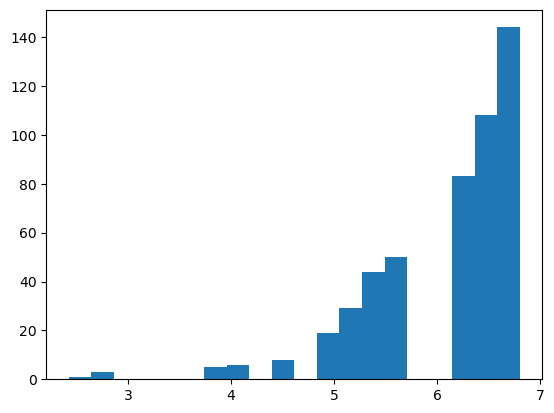

In [299]:
#plt.hist(qhat_dict['set_size_sd'][0])
#plt.hist(qhat_dict['set_size_sd'][1])
#plt.hist(qhat_dict['set_size_sd'][2])
#plt.hist(qhat_dict['set_size_sd'][3])
plt.hist(qhat_dict['set_size_sd'][1],20)

In [666]:
smx = smx_hqi(X_train, X_test, label_train)
cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(smx, label_test, cal_prop=0.9)

In [712]:
alpha = 0.1
n = cal_smx.shape[0]
(prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)

(prediction_sets.sum(1).mean(), empirical_coverage), qhat

((1.7894736842105263, 0.9473684210526315), 0.1635711210057592)

In [713]:
[(conform_pref(cal_smx, val_smx[0:1,:], cal_labels, n, alpha, val_labels)[0][0]).sum() for alpha in np.linspace(0.01,0.98, 50)]


[8,
 5,
 4,
 4,
 3,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [714]:
cal_scores = 1-cal_smx[np.arange(n),cal_labels]
alpha = 0.98
q_level = np.ceil((n+1)*(1-alpha))/n
np.quantile(cal_scores, q_level, method='higher')

0.003512547871152072

In [715]:
np.max(cal_scores)

0.5127694866355597

In [716]:
1-cal_smx[np.arange(n),cal_labels]

array([0.01781098, 0.01508079, 0.00938963, 0.01349654, 0.00734872,
       0.09398325, 0.01049909, 0.02834572, 0.01030318, 0.09449932,
       0.00705786, 0.03105677, 0.0369968 , 0.13279922, 0.2450669 ,
       0.14821716, 0.07152807, 0.10440845, 0.00996909, 0.01278841,
       0.01314988, 0.10167647, 0.01964973, 0.02802191, 0.11826053,
       0.10612987, 0.06065993, 0.04402379, 0.15900316, 0.08288939,
       0.00852709, 0.0076947 , 0.00492921, 0.00696209, 0.03353242,
       0.00528328, 0.01826233, 0.00128304, 0.03755794, 0.13072474,
       0.00533879, 0.07666344, 0.03742544, 0.01185951, 0.31233641,
       0.02440747, 0.22309405, 0.2255018 , 0.02343192, 0.07569278,
       0.20028899, 0.01473568, 0.01548293, 0.01202592, 0.01254685,
       0.01182433, 0.04860047, 0.03827848, 0.03319036, 0.01172931,
       0.02685111, 0.01655933, 0.02284827, 0.08706532, 0.00962918,
       0.02461284, 0.02123488, 0.01799457, 0.00351255, 0.00163342,
       0.00955861, 0.00241443, 0.01494865, 0.00470858, 0.00360

In [717]:
q_hat_table = np.array([[alpha, conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)[1]] for alpha in np.linspace(0.01,0.98, 50)])
q_hat_table.shape

(50, 2)

In [718]:
i=5
#np.where(np.array([(val_smx[i,:] >= (1-qhat)).sum() for qhat in q_hat_table[:,1]]) == 1)[0][-1]
no_one_sets = np.where([list(set(np.array([(val_smx[i,:] >= (1-qhat)).sum() for qhat in q_hat_table[:,1]])))[1] > 1 for i in range(val_smx.shape[0])])[0]
no_one_sets

array([10, 13])

In [719]:
no_zeros_sets = np.where([list(set(np.array([(val_smx[i,:] >= (1-qhat)).sum() for qhat in q_hat_table[:,1]])))[0] > 0 for i in range(val_smx.shape[0])])[0]
no_zeros_sets

array([ 1,  9, 10, 14])

In [720]:
c = np.array([np.sort(1-val_smx[i,:])[-2:] for i in range(val_smx.shape[0])])
c

array([[0.52405937, 0.53024431],
       [0.60897219, 0.70748368],
       [0.56728466, 0.75825528],
       [0.49797859, 0.76906109],
       [0.5131386 , 0.66160027],
       [0.52641605, 0.7285628 ],
       [0.84796299, 0.92433303],
       [0.64416537, 0.74341709],
       [0.88256548, 0.95649643],
       [0.46910494, 0.63399087],
       [0.65043786, 0.66496606],
       [0.50357391, 0.5382351 ],
       [0.63101552, 0.67444586],
       [0.60859295, 0.73824138],
       [0.61055087, 0.72071309],
       [0.61515612, 0.62153125],
       [0.65990753, 0.84561683],
       [0.54116733, 0.71152247],
       [0.35758297, 0.40287452]])

In [721]:
val_smx[0,:] > q

NameError: name 'q' is not defined

In [722]:
val_smx[0,:] 

array([0.57878628, 0.71241621, 0.46975569, 0.67199701, 0.48482604,
       0.81400517, 0.90440773, 0.48965162, 0.47594063, 0.83026406,
       0.79260217])

In [723]:
1-q_hat_table[0,1]

0.48723051336444034

In [724]:
a = 1-q_hat_table[[np.where([(val_smx[i,:] > 1-qhat).sum()>1 for qhat in q_hat_table[:,1]])[0][-1] + 1 for i in range(val_smx.shape[0])], 0]


In [725]:
b =1-q_hat_table[[min(np.where([(val_smx[i,:] > 1-qhat).sum()>0 for qhat in q_hat_table[:,1]])[0][-1] + 1,49) for i in range(val_smx.shape[0])], 0]


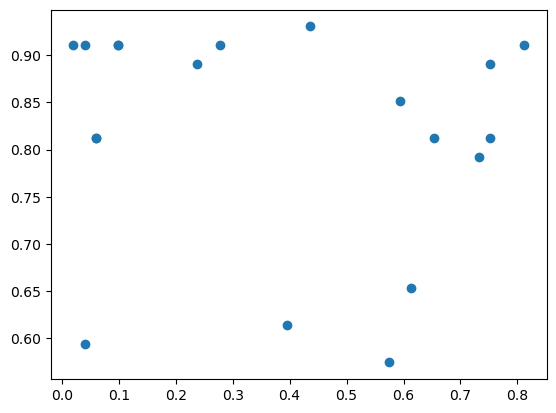

In [726]:
plt.scatter(b,a)

In [740]:
i_min, i_max = (
    np.argmin(a),
    np.argmax(a)
)
np.min(a), np.max(a)

(0.5742857142857143, 0.9306122448979592)

In [755]:
i_min, i_max = (
    np.argmin(b),
    np.argmax(b)
)
np.min(b), np.max(b)

(0.020000000000000018, 0.8118367346938775)

In [750]:
1-q_hat_table[5,1]

0.8376772164606602

In [756]:
val_smx[i_min,:]

array([0.54112335, 0.59881226, 0.44385596, 0.54895739, 0.34956214,
       0.99672317, 0.74240944, 0.33503394, 0.4128949 , 0.76395232,
       0.79806985])

In [757]:
val_smx[i_max,:]

array([0.52853307, 0.87561295, 0.37846875, 0.42865846, 0.57487516,
       0.58518791, 0.59764403, 0.41394766, 0.38484388, 0.77756759,
       0.73903134])

In [758]:
prediction_sets[i_min]

array([False, False, False, False, False,  True, False, False, False,
       False, False])

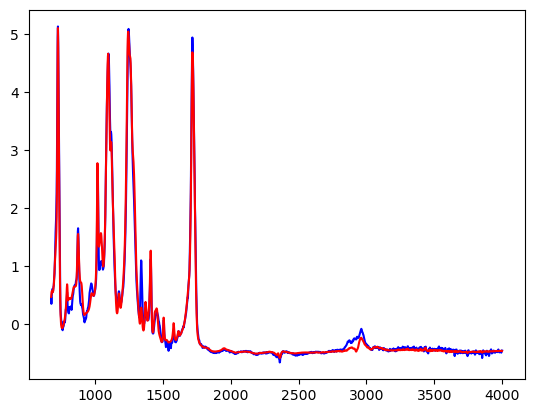

In [759]:
pred_hqi, score_hqi = np.argmax(val_smx, 1), np.max(val_smx, 1)
pred_hqi_poly = np.array(label_table.iloc[pred_hqi, 1])

plt.plot(wl_list, -X_test[~idx][i_min,:], c='b', label=label_table.iloc[val_labels[i_min],1])
plt.plot(wl_list, -X_train[label_train==pred_hqi[i_min]][0,:], c='r')#, alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi[i]*100)))


In [760]:
prediction_sets[i_max]

array([False,  True, False, False, False, False, False, False, False,
       False, False])

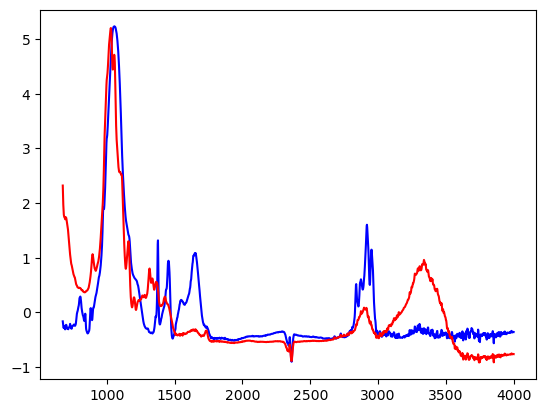

In [761]:
pred_hqi, score_hqi = np.argmax(val_smx, 1), np.max(val_smx, 1)
pred_hqi_poly = np.array(label_table.iloc[pred_hqi, 1])

plt.plot(wl_list, -X_test[~idx][i_max,:], c='b', label=label_table.iloc[val_labels[i_max],1])
plt.plot(wl_list, -X_train[label_train==pred_hqi[i_max]][0,:], c='r')#, alpha=.5, label=str(pred_hqi_poly[i]) + '-' + str(round(score_hqi[i]*100)))
